<a id="2"></a>
<h1 style='background:#87d3f8;border:0; color:black;
    box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.75);
    transform: rotateX(10deg);
    '><center style='color: #1f262a;'>Importações</center></h1>
    
## Importação dos módulos necessários

In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import matplotlib 
import numpy as np


from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import SGD
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from matplotlib import pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, precision_score, accuracy_score, recall_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.svm import SVC

from warnings import simplefilter
simplefilter(action='ignore', category=FutureWarning)

<a id="2"></a>
<h1 style='background:#87d3f8;border:0; color:black;
    box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.75);
    transform: rotateX(10deg);
    '><center style='color: #1f262a;'>Dataset</center></h1>
    
## Leitura dos dados

In [2]:
df = pd.read_csv("predictive_maintenance.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


<a id="2"></a>
<h1 style='background:#87d3f8;border:0; color:black;
    box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.75);
    transform: rotateX(10deg);
    '><center style='color: #1f262a;'>Análise dos dados</center></h1>
    
## Compreensão dos dados

Para a compreensão do conjunto de dados, iniciamos por investigar algumas informações relevantes, como, por exemplo, o formato do dataset, o tipo dados de cada atributo e a presença de valores nulos e duplicados. 

In [3]:
# numero de linhas e de colunas
df.shape

(10000, 10)

O dataset é composto por 10000 instâncias e 10 atributos.

In [4]:
# descrição dos atributos
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Target', 'Failure Type'],
      dtype='object')

In [5]:
# valores nulos e tipo de dados
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [6]:
# informações extra
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Target,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0


In [7]:
df['Failure Type'].value_counts()

No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: Failure Type, dtype: int64

In [8]:
df['Target'].value_counts()

0    9661
1     339
Name: Target, dtype: int64

In [9]:
# valores duplicados 
n= df.shape[0]

if df['UDI'].unique().shape[0] == n:
    print('Não existem valores duplicados na coluna "UDI".')
else:
    print('Existem valores duplicados na coluna "UDI".')
    
if df['Product ID'].unique().shape[0] == n:
    print('Não existem valores duplicados na coluna "Product ID".')
else:
    print('Existem valores duplicados na coluna "Product ID".')
    

Não existem valores duplicados na coluna "UDI".
Não existem valores duplicados na coluna "Product ID".


#### Visualização de algumas relações nos dados

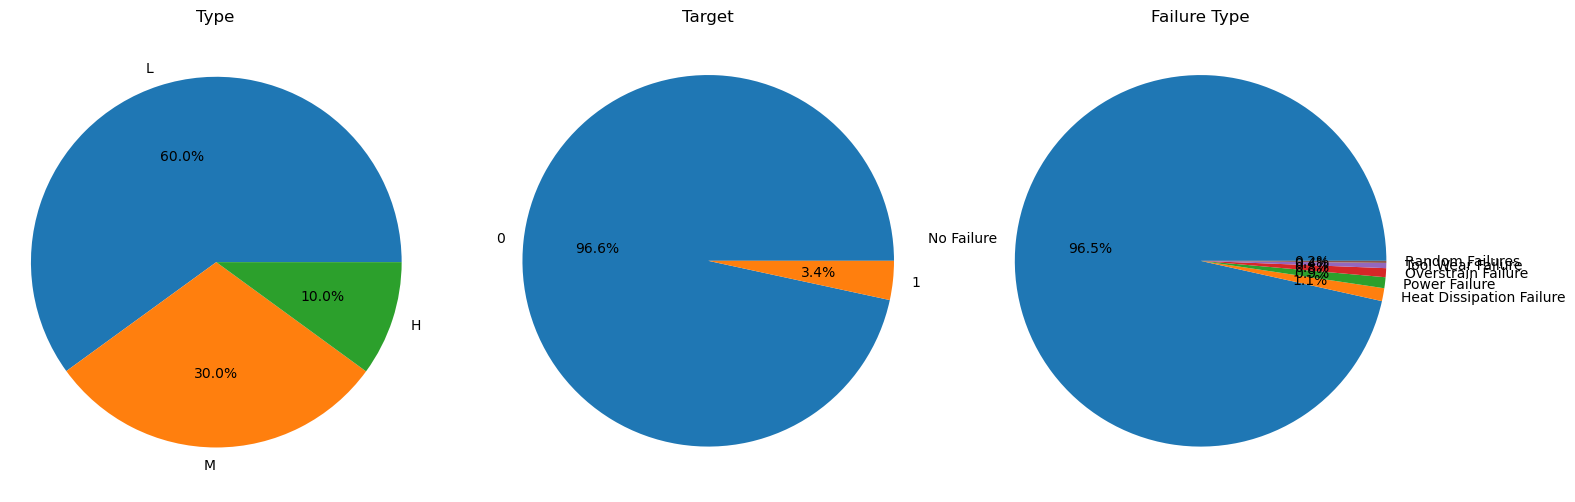

In [10]:
plt.figure(figsize=(18, 6))

# Visualização da dispersão da coluna 'Type'
plt.subplot(131)
contagem= df['Type'].value_counts()
plt.pie(contagem, labels= contagem.index, autopct='%1.1f%%')
plt.title('Type')
plt.axis('equal')

# Visualização da dispersão da coluna 'Target'
plt.subplot(132)
contagem= df['Target'].value_counts()
plt.pie(contagem, labels= contagem.index, autopct='%1.1f%%')
plt.title('Target')
plt.axis('equal')

# Visualização da dispersão da coluna 'Failure Type'
plt.subplot(133)
contagem= df['Failure Type'].value_counts()
plt.pie(contagem, labels= contagem.index, autopct='%1.1f%%')
plt.title('Failure Type')
plt.axis('equal')

plt.show()

O primeiro gráfico revela que o atributo 'Type' possui três valores possíveis, sendo o tipo 'L' predominante.  
Os outros dois gráficos indicam um desequilíbrio significativo nas classes das variáveis 'Target' e 'Failure Type'. A classe 0 representa a maioria dos dados para 'Target', enquanto a classe 'No Failure' é a mais comum para 'Failure Type', ambas com uma percentagem próxima de 100%.  

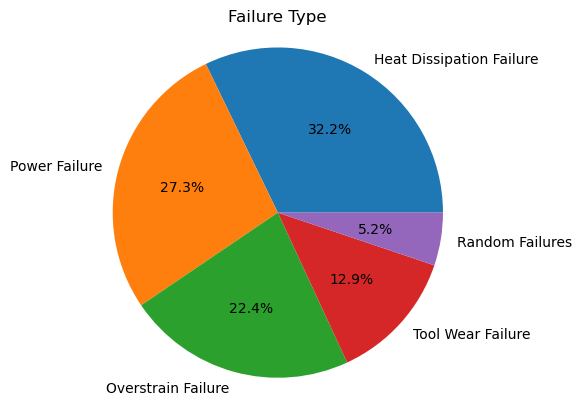

In [11]:
# Visualização da dispersão da coluna 'Failure Type' sem considerar a classe 'No Failure'
contagem = df[df['Failure Type'] != 'No Failure']['Failure Type'].value_counts()
plt.pie(contagem, labels=contagem.index, autopct='%1.1f%%')
plt.title('Failure Type')
plt.axis('equal')
plt.show()

In [12]:
# Relação entre os atributos 'Failure Type' e 'Target'
px.histogram(data_frame=df, x='Failure Type', color='Target',color_discrete_sequence=['#636EFA', '#EF553B', '#00CC96', '#AB63FA', '#FFA15A', '#19D3F3'])

A partir da análise deste gráfico, é possível inferir a presença de dados ambíguos no conjunto de dados. Observa-se que existem valores que são classificados como "falha" na variável 'Target', mas como "No Failure" na variável 'Failure Type', e também valores classificados como 'Random Failures' na variável 'Failure Type' que são classificados como "não falha" na variável 'Target'.

##### Conclusões superficiais:
  
    - Existem 10000 instâncias e 10 atributos.  
    - Existem 7 atributos numéricos e 3 atributos categóricos.  
    - Não existem dados em falta.  
    - O atributo 'Target' apresenta dois valores possíveis: 0 e 1.  
    - O atributo 'Failure Type' assume seis valores possíveis: nenhuma falha ou cinco tipos de falha.  
    - Da visualização da dispersão das duas variáveis de saída é possível concluir que o conjunto de dados é desbalanceado.
    - O atributo 'UDI' é semelhante ao índice de um dataframe.  
    - Não existem dados duplicados.  
    - Existem valores amíguos no dataset.

<a id="2"></a>
<h1 style='background:#87d3f8;border:0; color:black;
    box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.75);
    transform: rotateX(10deg);
    '><center style='color: #1f262a;'>Pré-processamento</center></h1>

Durante a etapa de pré-processamento realizaremos uma serie de experiencias para determinar qual é o método de pré-processamento que resulta nos melhores resultados. 
No final desta etapa vamos realizar uma análise para inferir qual é a melhor experinência para as duas variáveis de saída: 'Target', 'Failure Type'.      
  
As experiências vão ser as seguintes:    
  
1- Sem alterar nada  
2- Escalonamento  
3- Oversampling (10%, 20%, 30%, 40%, 50% e 60%)    
4- Seleção de Variáveis     
5- Escalonamento + Oversampling  
6- Escalonamento + Oversampling + Seleção de Variáveis  

O resultado da melhor experiencia vai ser utilizado na etapa de modelização. 


### Anomalias nas variáveis de saída

Nesta etapa, iremos aprofundar as conclusões acerca das dispersões das variáveis de saída, a fim de verificar se existe alguma anomalia.

In [13]:
df['Failure Type'].value_counts()

No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: Failure Type, dtype: int64

É possível verificar que a opção 'No Failure' na variável 'Failure Type' corresponde ao valor 0 na variável 'Target'. Dessa forma, iremos verificar se existe alguma inconsistência entre as duas variáveis.

In [14]:
# indices dos valores ambíguos
indices= df.loc[(df['Target']==1) & (df['Failure Type']=='No Failure')].index
# número de registos com valores ambíguos
num = indices.value_counts().sum()
print('Número de registos com valores ambíguos:', num)
df.loc[indices, ['Target', 'Failure Type']]

Número de registos com valores ambíguos: 9


,Target,Failure Type
1437,1,No Failure
2749,1,No Failure
4044,1,No Failure
4684,1,No Failure
5536,1,No Failure
5941,1,No Failure
6478,1,No Failure
8506,1,No Failure
9015,1,No Failure


Existem nove valores que são classificados como falha na variável 'Target', mas como No Failure na variável 'Failure Type'. Como não sabemos se houve falha ou não na máquina, vamos eliminar estes nove registos do dataset.

In [15]:
# Eliminação
df.drop(index=indices, inplace=True)
df.shape

(9991, 10)

Verifiquemos agora o mesmo para o caso em que a variável 'Target' é zero (sem falha).

In [16]:
df_zero = df[df['Target'] == 0]
df_zero['Failure Type'].value_counts()

No Failure         9643
Random Failures      18
Name: Failure Type, dtype: int64

In [17]:
ind_rf = df.loc[df['Failure Type']=='Random Failures'].index
df.loc[ind_rf, ['Target', 'Failure Type']]

,Target,Failure Type
1221,0,Random Failures
1302,0,Random Failures
1748,0,Random Failures
2072,0,Random Failures
2559,0,Random Failures
3065,0,Random Failures
3452,0,Random Failures
5471,0,Random Failures
5489,0,Random Failures
5495,0,Random Failures


Foi constatado que todos os registros classificados como 'Random Failures' na variável 'Failure Type' são classificados como 'não falha' na variável 'Target'. Como esses 18 registros têm uma natureza aleatória e imprevisível, não é possível determinar se eles pertencem ou não a um tipo de falha. Diante disso, decidiu-se remover esses registros completamente do conjunto de dados.   
  
Assim sendo, restarão apenas quatro tipos de falhas, uma vez que as falhas aleatórias serão eliminadas por completo.

In [18]:
# Eliminação
df.drop(index=ind_rf, inplace=True)
df.shape

(9973, 10)

### Tratamento de variáveis categóricas

Anteriormente, foi constatado que existem três atributos categóricos que devem ser convertidos em atributos númericos ou eliminados, caso não sejam relevantes para o estudo em causa, a fim de realizar a análise do conjunto de dados.  
  
Em relação ao atributo 'Product ID', verificou-se que os seus valores são compostos por uma letra inicial (L, M ou H), seguida de um número serial específico. Inicialmente, vamos retirar a letra inicial, uma vez que, já existe um atributo 'Type' que contém essa informação. Em  seguida, converteremos o número restante para um formato numérico e verificaremos se existem valores duplicados, ou seja, se o mesmo número serial é atribuído a diferentes variantes.  
Caso não existam e considerando que não há padrões ocultos por trás deste número, procederemos a remoção deste atributo. Uma vez que se trata de um identificador único de cada registo, a sua remoção não afetará a previsão de ocorrência de falha na máquina ou tipo de falha que ocorreu.

Quanto aos atributos 'Type' e 'Failure Type', procederemos à sua transformação em formato numérico. Para o atributo 'Type', substituiremos os valores L, M e H por 1, 2 e 3, respectivamente. Já para o atributo 'Failure Type', substituiremos os valores 'No Failure', 'Power Failure', 'Tool Wear Failure', 'Overstrain Failure' e 'Heat Dissipation Failure' por 0, 1, 2, 3 e 4, respectivamente.



##### Coluna 'Product ID'

In [19]:
# Remoção da letra e conversão do restante para formato numérico
x = df.shape[0]
df['Product ID'] = df['Product ID'].apply(lambda d: d[1:]) # remoção
df['Product ID'] = pd.to_numeric(df['Product ID']) # conversão

if df['Product ID'].unique().shape[0] == x:
    print('Não existem valores duplicados na coluna "Product ID".')
else:
    print('Existem valores duplicados na coluna "Product ID".')

Não existem valores duplicados na coluna "Product ID".


##### Coluna 'Type'

In [20]:
# codificação
df['Type'] = df['Type'].map({'L':0, 'M':1, 'H':2})
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,14860,1,298.1,308.6,1551,42.8,0,0,No Failure
1,2,47181,0,298.2,308.7,1408,46.3,3,0,No Failure
2,3,47182,0,298.1,308.5,1498,49.4,5,0,No Failure
3,4,47183,0,298.2,308.6,1433,39.5,7,0,No Failure
4,5,47184,0,298.2,308.7,1408,40.0,9,0,No Failure
...,...,...,...,...,...,...,...,...,...,...
9995,9996,24855,1,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,39410,2,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,24857,1,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,39412,2,299.0,308.7,1408,48.5,25,0,No Failure


##### Coluna 'Failure Type'

In [21]:
# codificação
df['Failure Type'] = df['Failure Type'].map({'No Failure': 0,
              'Power Failure': 1,
              'Tool Wear Failure': 2,
              'Overstrain Failure': 3,
              'Heat Dissipation Failure': 4})
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,14860,1,298.1,308.6,1551,42.8,0,0,0
1,2,47181,0,298.2,308.7,1408,46.3,3,0,0
2,3,47182,0,298.1,308.5,1498,49.4,5,0,0
3,4,47183,0,298.2,308.6,1433,39.5,7,0,0
4,5,47184,0,298.2,308.7,1408,40.0,9,0,0
...,...,...,...,...,...,...,...,...,...,...
9995,9996,24855,1,298.8,308.4,1604,29.5,14,0,0
9996,9997,39410,2,298.9,308.4,1632,31.8,17,0,0
9997,9998,24857,1,299.0,308.6,1645,33.4,22,0,0
9998,9999,39412,2,299.0,308.7,1408,48.5,25,0,0


### Eliminação de atributos redundantes

Após a análise realizada, constatou-se que não existem valores duplicados do número serial no atributo 'Product ID', o que o torna um identificador único de cada registo. Dessa forma, a remoção deste atributo não afetará a previsão de ocorrência na máquina ou tipo de falha que ocorreu.  
  
Por outro lado, no que diz respeito ao atributo 'UDI', verificou-se que se trata de uma cópia do índice do dataframe "df". Sendo assim, esta informação é redundante e não traz contribuições relevantes para a análise dos dados em questão. Portanto, este atributo também pode ser removido do dataset.

In [22]:
df1= df.copy()
df1.drop(columns= ['UDI', 'Product ID'], inplace= True)
df1

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,298.1,308.6,1551,42.8,0,0,0
1,0,298.2,308.7,1408,46.3,3,0,0
2,0,298.1,308.5,1498,49.4,5,0,0
3,0,298.2,308.6,1433,39.5,7,0,0
4,0,298.2,308.7,1408,40.0,9,0,0
...,...,...,...,...,...,...,...,...
9995,1,298.8,308.4,1604,29.5,14,0,0
9996,2,298.9,308.4,1632,31.8,17,0,0
9997,1,299.0,308.6,1645,33.4,22,0,0
9998,2,299.0,308.7,1408,48.5,25,0,0


### Outliers

O objetivo desta etapa é realizar uma verificação de possíveis outliers no conjunto de dados, uma vez que esses valores atípicos podem ser prejudiciais para algoritmos de aprendizado de máquina. Para isso, começamos por examinar um relatório estatístico das características numéricas do conjunto de dados.

In [23]:
df1.describe().T

,count,mean,std,min,25%,50%,75%,max
Type,9973.0,0.500050,0.670959,0.0,0.0,0.0,1.0,2.0
Air temperature [K],9973.0,300.003259,2.000548,295.3,298.3,300.1,301.5,304.5
Process temperature [K],9973.0,310.004031,1.483692,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],9973.0,1538.893212,179.412171,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],9973.0,39.978993,9.966805,3.8,33.2,40.1,46.7,76.6
Tool wear [min],9973.0,107.921087,63.649152,0.0,53.0,108.0,162.0,253.0
Target,9973.0,0.033089,0.178879,0.0,0.0,0.0,0.0,1.0
Failure Type,9973.0,0.086935,0.519730,0.0,0.0,0.0,0.0,4.0


Com base no relatório estatístico, é possível identificar a presença de possíveis outliers na variável 'Rotational speed [rpm]', porque existe uma grande diferença entre o valor máximo observado (2886 rpm) e o terceiro quartil (1612 rpm), sugerindo uma grande dispersão dos dados. Para sustentar essa hipótese, realizemos uma análise mais completa e robusta, utilizando gráficos boxplot e histograma. 

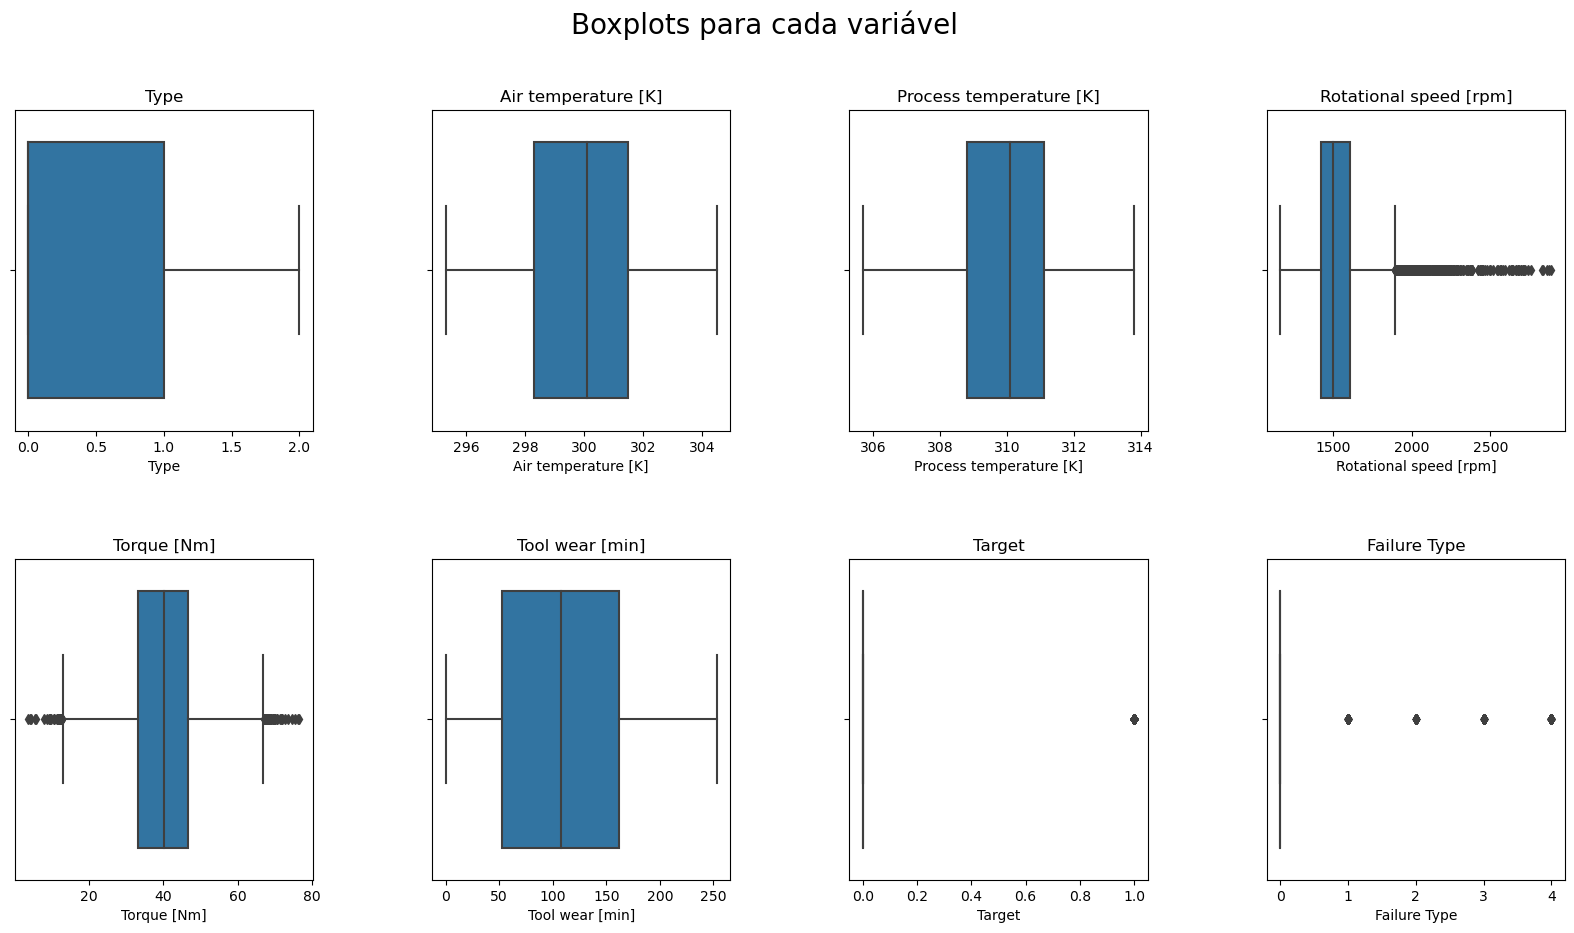

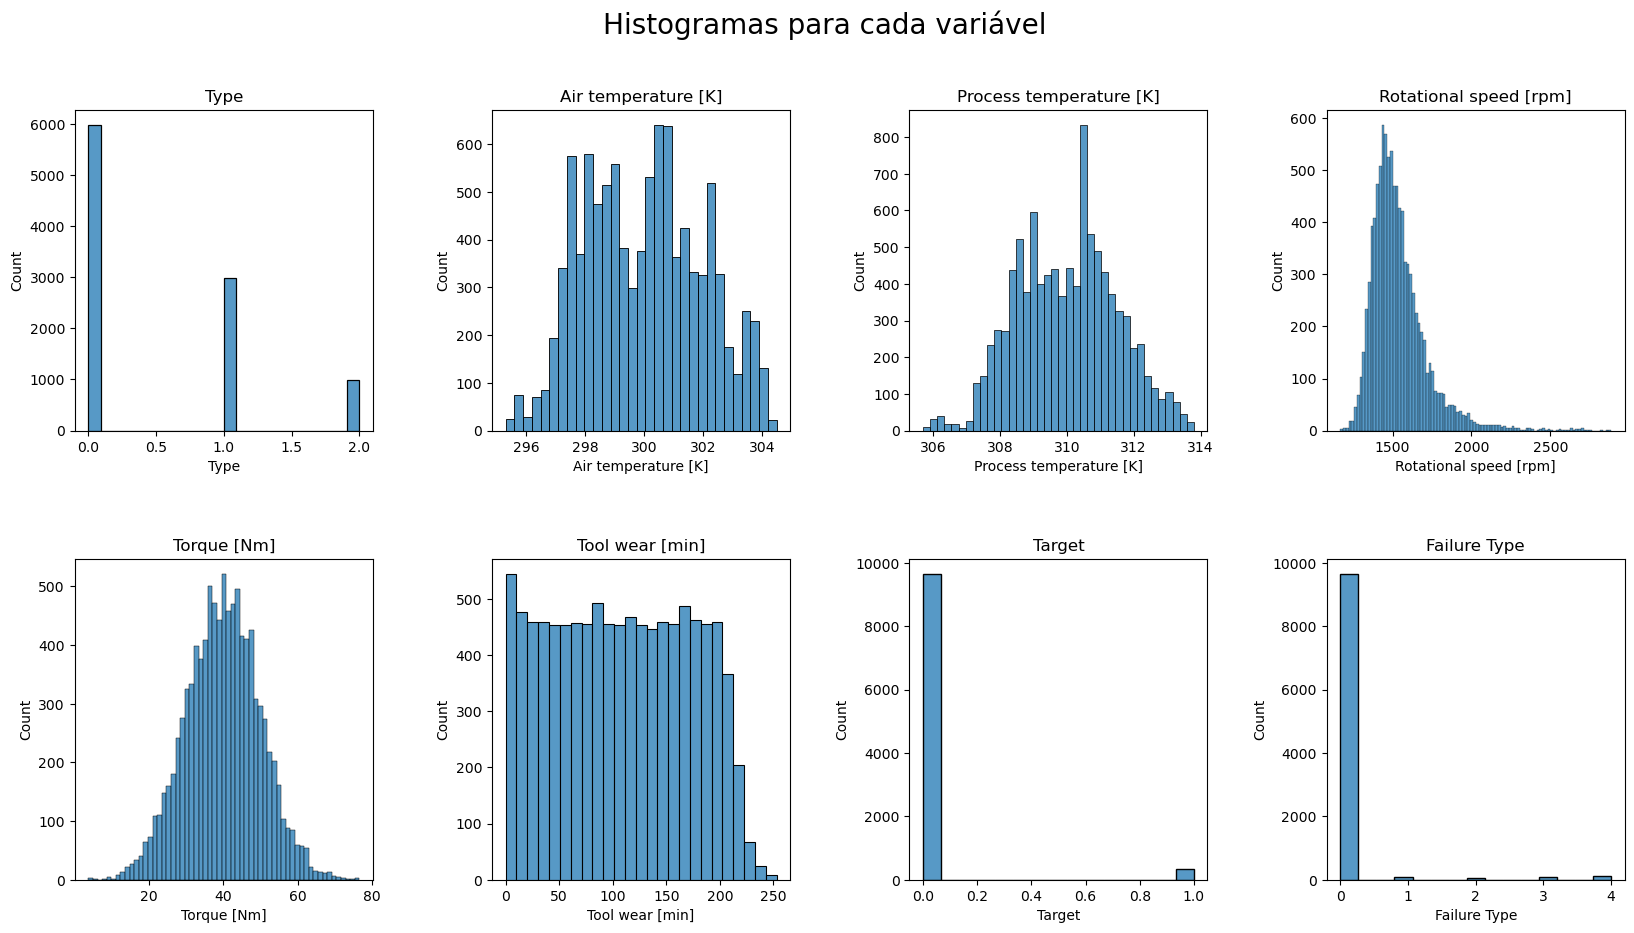

In [24]:
# cria a figura e os subplots para os boxplots
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
plt.subplots_adjust(wspace=0.4, hspace=0.4)

# plota os boxplots em cada subplot
for i, var in enumerate(df1.columns):
    sns.boxplot(x=df1[var], ax=axes[i])
    axes[i].set_title(var)

fig.suptitle('Boxplots para cada variável', fontsize=20)
    
# cria a figura e os subplots para os histogramas
fig2, axes2 = plt.subplots(2, 4, figsize=(20, 10))
axes2 = axes2.flatten()
plt.subplots_adjust(wspace=0.4, hspace=0.4)

# plota os histogramas em cada subplot
for i, var in enumerate(df1.columns):
    sns.histplot(x=df1[var], ax=axes2[i])
    axes2[i].set_title(var)

fig2.suptitle('Histogramas para cada variável', fontsize=20)

plt.show()

Com base na análise dos boxplots e dos histogramas, é possível identificar possíveis outliers nas variáveis 'Torque' e 'Rotational Speed'. No entanto, foi verificado que a distribuição dos dados na variável 'Torque' segue uma distribuição normal, o que sugere que a presença de valores extremos pode ser apenas uma variação natural da distribuição. Já na variável 'Rotational Speed', a distribuição não é simétrica.  
Apesar da presença de possíveis outliers nessas variáveis, vamos optar por mantê-los por enquanto, pois eles podem não ser, de facto, outliers.  
Agora, vamos verificar a distribuição das variáveis de entrada 'Torque [Nm]' e 'Rotational speed [rpm]' em relação às variáveis de saída.

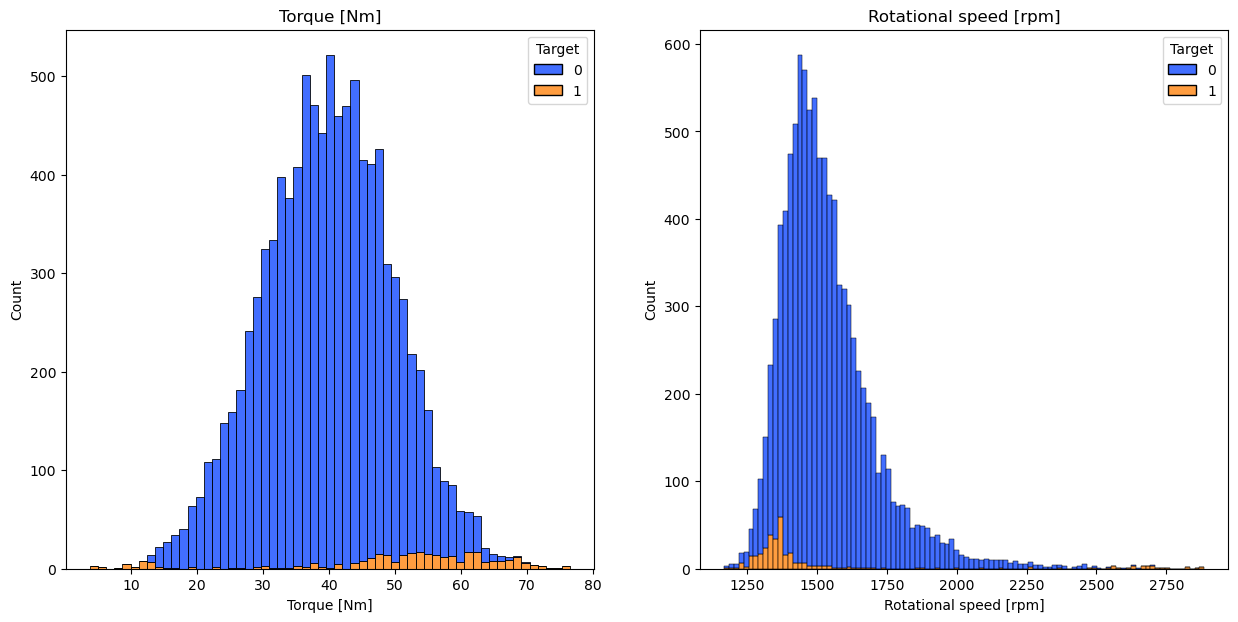

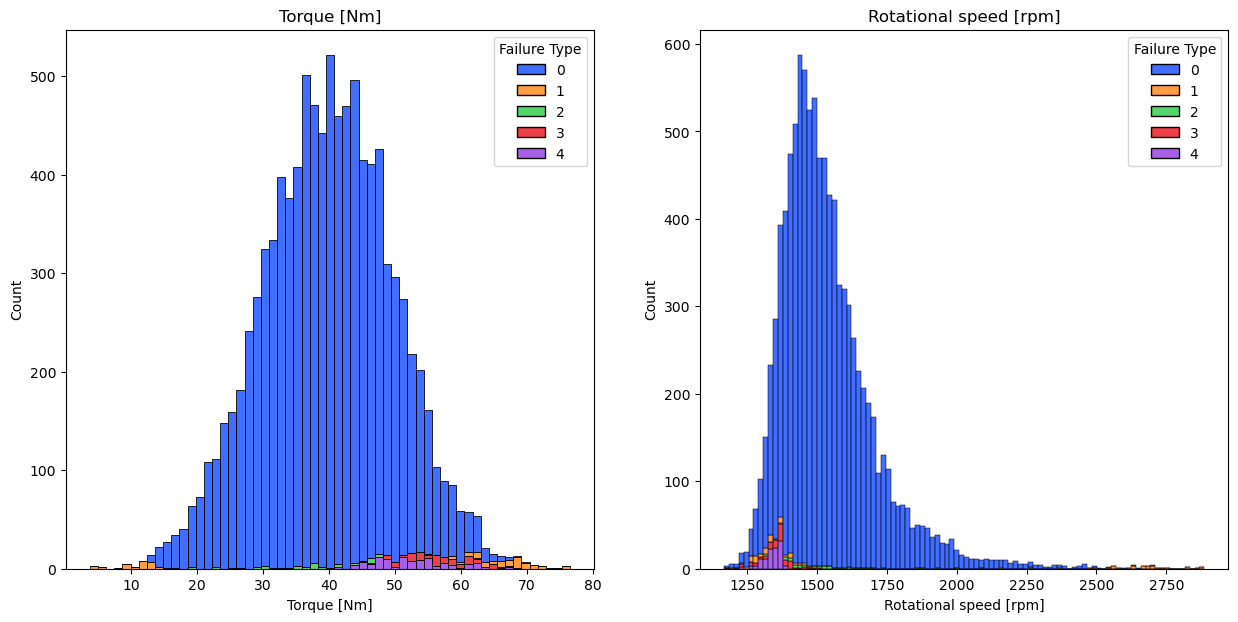

In [25]:
# Visualização da distribuição relativamente à variável de saída 'Target'
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,7))
sns.histplot(ax=axs[0], data=df1, x='Torque [Nm]', hue='Target', multiple='stack', palette='bright')
sns.histplot(ax=axs[1], data=df1, x='Rotational speed [rpm]', hue='Target', multiple='stack', palette='bright')
axs[0].set_title('Torque [Nm]')
axs[1].set_title('Rotational speed [rpm]')
plt.show()

# Visualização da distribuição relativamente à variável de saída 'Failure Type'
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,7))
sns.histplot(ax=axs[0], data=df1, x='Torque [Nm]', hue='Failure Type', multiple='stack', palette='bright')
sns.histplot(ax=axs[1], data=df1, x='Rotational speed [rpm]', hue='Failure Type', multiple='stack', palette='bright')
axs[0].set_title('Torque [Nm]')
axs[1].set_title('Rotational speed [rpm]')
plt.show()

Com base na análise dos histogramas, é possível observar que os registos de falhas e tipos de falhas nas máquinas estão concentrados nas extremidades das distribuições das duas variáveis de entrada analisadas. Isso sugere que os valores extremos de torque e velocidade rotacional podem ser os responsáveis pelas falhas nas máquinas. Portanto, os possíveis outliers identificados na etapa anterior podem não ser erros, mas sim uma variação natural dos dados. Consequentemente, não será necessário removê-los.

### Experiências 

In [26]:
# Esta função tem como objetivo treinar o modelo utilizado nos testes das experiências, 
# bem como no processo de validação subsequente.

def treino_modelo(model, X_train, y_train, X_test,y_test):
    
    model.fit(X_train, y_train) # treino do modelo
    
    predictions = model.predict(X_test) # calculo das previsões
    
    matriz_confusao = confusion_matrix(y_test, predictions)
    # criação das métricas para avaliar o modelo
    accuracy = accuracy_score(y_test, predictions) * 100
    f1 = f1_score(y_test, predictions, average='macro') * 100
    precision = precision_score(y_test, predictions, average='macro', zero_division=1) * 100
    recall = recall_score(y_test, predictions, average='macro') * 100
    
    # criação de um dataframe para a visualização dos resultados
    resul = pd.DataFrame([[accuracy, f1, precision, recall]], columns=['accuracy', 'f1_score', 'precision', 'recall'])
    print("-----------------------------------------------")
    print("Matriz de Confusão:")
    print(matriz_confusao)
    print("-----------------------------------------------")
    print(resul)
    print("-----------------------------------------------")

#### 1ª Experiência (Sem nada)

In [27]:
df_exp1 = df1.copy()

###### Variável Target  (1ª Experiência)

In [28]:
model = RandomForestClassifier()

X = df_exp1.drop(['Target','Failure Type'], axis = 1)
y = df_exp1['Target']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=55,stratify=None)

treino_modelo(model,X_train, y_train, X_test, y_test)

-----------------------------------------------
Matriz de Confusão:
[[2888    7]
 [  39   58]]
-----------------------------------------------
    accuracy   f1_score  precision     recall
0  98.462567  85.407416  93.949173  79.776009
-----------------------------------------------


###### Variável Failure Type (1ª Experiência)

In [29]:
model = RandomForestClassifier()

X = df_exp1.drop(['Target','Failure Type'], axis = 1)
y = df_exp1['Failure Type']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=55,stratify=None)

treino_modelo(model,X_train, y_train, X_test, y_test)

-----------------------------------------------
Matriz de Confusão:
[[2890    4    0    1    0]
 [   6   17    0    0    0]
 [  13    0    0    1    0]
 [  12    1    0   15    0]
 [   6    0    0    3   23]]
-----------------------------------------------
    accuracy   f1_score  precision     recall
0  98.429144  64.194104  90.201727  59.837352
-----------------------------------------------


### Escalonamento de variáveis

Como as variáveis de entrada possuem escalas muito diferentes, é importante que elas sejam escalonadas antes de implementarmos os modelos, a fim de evitar impactos negativos no desempenho. Apesar de termos considerado anteriormente que os valores extremos nas variáveis 'Torque' e 'Rotational Speed' são uma variação normal dos dados, optamos por utilizar o escalonador 'RobustScaler', por sua capacidade de lidar melhor com esses valores. Isso nos ajudará a evitar que possíveis ruídos afetem a performance dos modelos. Já para as demais variáveis, que não apresentam valores discrepantes, utilizaremos o escalonador 'MinMaxScaler', mais adequado para esse tipo de dados.

#### 2ª Experiencia (Escalonamento)

In [30]:
df_exp2 = df1.copy()

In [31]:
var_rs = ['Torque [Nm]', 'Rotational speed [rpm]']
scaler = RobustScaler()
df_exp2[var_rs] = scaler.fit_transform(df_exp2[var_rs])
df_exp2

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,298.1,308.6,0.253968,0.200000,0,0,0
1,0,298.2,308.7,-0.502646,0.459259,3,0,0
2,0,298.1,308.5,-0.026455,0.688889,5,0,0
3,0,298.2,308.6,-0.370370,-0.044444,7,0,0
4,0,298.2,308.7,-0.502646,-0.007407,9,0,0
...,...,...,...,...,...,...,...,...
9995,1,298.8,308.4,0.534392,-0.785185,14,0,0
9996,2,298.9,308.4,0.682540,-0.614815,17,0,0
9997,1,299.0,308.6,0.751323,-0.496296,22,0,0
9998,2,299.0,308.7,-0.502646,0.622222,25,0,0


In [32]:
var_mMs = ['Air temperature [K]', 'Process temperature [K]', 'Tool wear [min]']
scaler = MinMaxScaler()
df_exp2[var_mMs] = scaler.fit_transform(df_exp2[var_mMs])
df_exp2

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,0.304348,0.358025,0.253968,0.200000,0.000000,0,0
1,0,0.315217,0.370370,-0.502646,0.459259,0.011858,0,0
2,0,0.304348,0.345679,-0.026455,0.688889,0.019763,0,0
3,0,0.315217,0.358025,-0.370370,-0.044444,0.027668,0,0
4,0,0.315217,0.370370,-0.502646,-0.007407,0.035573,0,0
...,...,...,...,...,...,...,...,...
9995,1,0.380435,0.333333,0.534392,-0.785185,0.055336,0,0
9996,2,0.391304,0.333333,0.682540,-0.614815,0.067194,0,0
9997,1,0.402174,0.358025,0.751323,-0.496296,0.086957,0,0
9998,2,0.402174,0.370370,-0.502646,0.622222,0.098814,0,0


###### Variável Target  (2ª Experiência)

In [33]:
model = RandomForestClassifier()

X = df_exp2.drop(['Target','Failure Type'], axis = 1)
y = df_exp2['Target']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=55,stratify=None)

treino_modelo(model,X_train, y_train, X_test, y_test)

-----------------------------------------------
Matriz de Confusão:
[[2890    5]
 [  36   61]]
-----------------------------------------------
    accuracy  f1_score  precision     recall
0  98.629679  87.07114  95.596947  81.356943
-----------------------------------------------


###### Variável Failure Type (2ª Experiência)

In [34]:
model = RandomForestClassifier()

X = df_exp2.drop(['Target','Failure Type'], axis = 1)
y = df_exp2['Failure Type']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=55,stratify=None)

treino_modelo(model,X_train, y_train, X_test, y_test)

-----------------------------------------------
Matriz de Confusão:
[[2892    3    0    0    0]
 [   6   17    0    0    0]
 [  13    0    0    1    0]
 [  11    1    0   16    0]
 [   6    0    0    2   24]]
-----------------------------------------------
    accuracy   f1_score  precision     recall
0  98.562834  66.080472   92.78668  61.190455
-----------------------------------------------


### Desiquilíbrio das classes

Conforme discutido anteriormente, as variáveis 'Target' e 'Failure Type' apresentam desequilíbrio significativo entre as classes, com a maioria dos registos sendo classificados como 0 (indicando ausência de falha). Devido ao tamanho reduzido do conjunto de dados, contendo apenas 10.000 registos, há um risco substancial de ocorrer overfitting. É crucial que os modelos implementados sejam capazes de generalizar efetivamente para novos dados.  
  
Para abordar o desequilíbrio entre as classes, optaremos por empregar a técnica conhecida como SMOTE. Essa abordagem consiste em gerar dados sintéticos para a classe minoritária (presença de falha (1)). O método SMOTE opera selecionando aleatoriamente uma amostra da classe minoritária, identificando seus k vizinhos mais próximos e criando um novo ponto de dados ao adicionar um vetor multiplicado por um número aleatório entre 0 e 1 ao ponto de dados original. Com o intuito de obter os melhores resultados, realizaremos diversas experiências para avaliar diferentes percentagens de aumento para a classe minoritária.

#### 3ª Experiência (Oversampling)

In [35]:
df_over = df1.copy()

##### Variável de saída Target

In [36]:
def oversampling_target(df_over):
    # Definir as variáveis de entrada (features) e a variável alvo (target)
    X = df_over.drop(['Target', 'Failure Type'], axis=1)  # Variáveis de entrada
    y = df_over['Target']  # Variável alvo

    # Definir as percentagens de oversampling a testar
    percentagens = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

    # Criar o modelo
    random_forest = RandomForestClassifier()

    # Definir o número de repetições
    n_repeats = 5

    # Inicializar arrays para armazenar as médias das métricas
    mean_precisions = np.zeros(len(percentagens))
    mean_recalls = np.zeros(len(percentagens))
    mean_f1_scores = np.zeros(len(percentagens))
    mean_accuracy = np.zeros(len(percentagens))

    for i, percentagem in enumerate(percentagens):
        # Inicializar arrays para armazenar as métricas para cada repetição
        precisions = np.zeros(n_repeats)
        recalls = np.zeros(n_repeats)
        f1_scores = np.zeros(n_repeats)
        accuracys = np.zeros(n_repeats)
        matrizes_confusao = []

        # Realizar as repetições da validação cruzada
        for j in range(n_repeats):
            # Aplicar o split dos dados em treinamento e teste
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=j)

            # Aplicar o SMOTE apenas na classe minoritária (1)
            smote = SMOTE(sampling_strategy=percentagem, random_state=0)
            X_train_oversampled, y_train_oversampled = smote.fit_resample(X_train, y_train)

            # Treinar o modelo
            random_forest.fit(X_train_oversampled, y_train_oversampled)

            # Fazer previsões
            y_pred = random_forest.predict(X_test)

            model.fit(X_train, y_train) # treino do modelo
    
            # criação das métricas para avaliar o modelo
            accuracy = accuracy_score(y_test, y_pred) * 100
            f1 = f1_score(y_test, y_pred, average='macro') * 100
            precision = precision_score(y_test, y_pred, average='macro', zero_division=1) * 100
            recall = recall_score(y_test, y_pred, average='macro') * 100


            # Armazenar as métricas da repetição atual
            precisions[j] = precision
            recalls[j] = recall
            f1_scores[j] = f1
            accuracys[j] = accuracy

        # Calcular as médias das métricas para a percentagem atual
        mean_precisions[i] = np.mean(precisions)
        mean_recalls[i] = np.mean(recalls)
        mean_f1_scores[i] = np.mean(f1_scores)
        mean_accuracy[i] = np.mean(accuracys)
        

        # Imprimir os resultados
        print("Percentagem de oversampling:", percentagem * 100, "%")
        print("Média Precision:", round(mean_precisions[i],2))
        print("Média Recall:", round(mean_recalls[i],2))
        print("Média F1-score:", round(mean_f1_scores[i],2))
        print("Média Accuracy:", round(mean_accuracy[i],2))
        print("-------------------------------")

oversampling_target(df_over) 

Percentagem de oversampling: 10.0 %
Média Precision: 89.87
Média Recall: 85.79
Média F1-score: 87.68
Média Accuracy: 98.5
-------------------------------
Percentagem de oversampling: 20.0 %
Média Precision: 83.95
Média Recall: 87.59
Média F1-score: 85.65
Média Accuracy: 98.04
-------------------------------
Percentagem de oversampling: 30.0 %
Média Precision: 79.97
Média Recall: 87.38
Média F1-score: 83.21
Média Accuracy: 97.57
-------------------------------
Percentagem de oversampling: 40.0 %
Média Precision: 77.6
Média Recall: 87.98
Média F1-score: 81.88
Média Accuracy: 97.24
-------------------------------
Percentagem de oversampling: 50.0 %
Média Precision: 76.28
Média Recall: 87.7
Média F1-score: 80.84
Média Accuracy: 97.01
-------------------------------
Percentagem de oversampling: 60.0 %
Média Precision: 75.75
Média Recall: 87.5
Média F1-score: 80.39
Média Accuracy: 96.89
-------------------------------


Com base nos resultados fornecidos, onde cada percentagem (10%, 20%, 30%, 40%, 50% e 60%) de oversampling é testada e avaliada usando as métricas: Precision, Recall e F1-score, podemos analisar as métricas para identificar a melhor percentagem de oversampling para o seu objetivo de identificar máquinas com falhas.  
  
Os resultados podem variar à medida que o código é executado, no entanto para controlar melhor essa situação, fizemos 5 repetições e calculámos as médias das métricas, obtendo os seguintes resultados:
  
A percentagem de oversampling de 10% possui uma média de Precision de 89.19, Recall de 86.24, F1-score de 87.61 e Accuracy de 98.46.  
A percentagem de oversampling de 20% possui uma média de Precision de 83.9, Recall de 86.56, F1-score de 85.15 e Accuracy de 98.01.  
A percentagem de oversampling de 30% possui uma média de Precision de 79.82, Recall de 87.41, F1-score de 83.12 e Accuracy de 97.55.  
A percentagem de oversampling de 40% possui uma média de Precision de 77.06, Recall de 87.59, F1-score de 81.36 e Accuracy de 97.13.  
A percentagem de oversampling de 50% possui uma média de Precision de 76.49, Recall de 87.37, F1-score de 80.88 e Accuracy de 97.04.  
A percentagem de oversampling de 60% possui uma média de Precision de 74.46, Recall de 88.07, F1-score de 80.36 e Accuracy de 96.85.  
  
Considerando que o objetivo é identificar as máquinas com falhas, é importante ter um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, fornecendo uma visão geral do desempenho do modelo.  
  
Analisando os resultados, podemos observar que a percentagem de oversampling de 10% apresenta um bom equilíbrio entre a precisão (89.19) e o recall (86.24). Além disso, possui um F1-score médio de 87.61, que é uma medida adequada para avaliar o desempenho geral do modelo.  
  
Portanto, com base nas métricas apresentadas e considerando o objetivo de identificar as máquinas com falhas, a percentagem de oversampling de 10% parece ser a melhor escolha, pois oferece um bom equilíbrio entre precisão e recall, o que é essencial para identificar corretamente as máquinas com falhas.  

#### Variável de saída Failure Type

In [37]:
def oversampling_failure(df_over):    
    # Definir as variáveis de entrada (features) e a variável alvo (target)
    X = df_over.drop(['Target', 'Failure Type'], axis=1)  # Variáveis de entrada
    y = df_over['Failure Type']  # Variável alvo

    # Aplicar o split dos dados em treinamento e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

    # Definir as percentagens de aumento das classes minoritárias
    percentagens = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

    # Criar o modelo
    random_forest = RandomForestClassifier()

    # Loop sobre as percentagens
    for percentagem in percentagens:
        # Calcular o número médio de amostras necessário para as classes minoritárias
        minoritaria_count = int((percentagem / 4) * len(y_train))

        # Definir a estratégia de oversampling para as classes minoritárias
        balance_cause = {
            1: minoritaria_count,
            2: minoritaria_count,
            3: minoritaria_count,
            4: minoritaria_count
        }

        # Aplicar o SMOTE nas classes minoritárias
        smote = SMOTE(sampling_strategy=balance_cause, random_state=0)
        X_train_oversampled, y_train_oversampled = smote.fit_resample(X_train, y_train)

        # Treinar o modelo
        random_forest.fit(X_train_oversampled, y_train_oversampled)

        # Fazer previsões
        y_pred = random_forest.predict(X_test)

        matriz_confusao = confusion_matrix(y_test, y_pred)
        # criação das métricas para avaliar o modelo
        accuracy = accuracy_score(y_test, y_pred) * 100
        f1 = f1_score(y_test, y_pred, average='macro') * 100
        precision = precision_score(y_test, y_pred, average='macro', zero_division=1) * 100
        recall = recall_score(y_test, y_pred, average='macro') * 100

        # Imprimir os resultados
        print("Percentagem de oversampling:", percentagem * 100, "%")
        print("Matriz de Confusão:")
        print(matriz_confusao)
        print("Precision:", round(precision,2))
        print("Recall:", round(recall,2))
        print("F1-score:", round(f1,2))
        print("Accuracy:", round(accuracy,2))
        print("-------------------------------")

oversampling_failure(df_over)

Percentagem de oversampling: 10.0 %
Matriz de Confusão:
[[2871    3   10    1    4]
 [   4   24    0    2    0]
 [  13    0    0    0    0]
 [   9    0    0   15    0]
 [   8    1    0    0   27]]
Precision: 70.99
Recall: 63.38
F1-score: 66.78
Accuracy: 98.16
-------------------------------
Percentagem de oversampling: 20.0 %
Matriz de Confusão:
[[2865    3   12    5    4]
 [   5   24    0    1    0]
 [  12    0    1    0    0]
 [   7    0    0   16    1]
 [   6    1    0    0   29]]
Precision: 70.08
Recall: 66.82
F1-score: 68.39
Accuracy: 98.09
-------------------------------
Percentagem de oversampling: 30.0 %
Matriz de Confusão:
[[2857    5   19    3    5]
 [   3   25    1    1    0]
 [  12    0    1    0    0]
 [   5    0    0   18    1]
 [   6    1    0    0   29]]
Precision: 69.84
Recall: 69.09
F1-score: 69.36
Accuracy: 97.93
-------------------------------
Percentagem de oversampling: 40.0 %
Matriz de Confusão:
[[2849    6   24    5    5]
 [   5   24    0    1    0]
 [   9    0 

Para a variável de saída "Failure Type", foram testadas as mesmas percentagens e avaliadas as mesmas métricas. Os resultados obtidos foram os seguintes:
  
A percentagem de oversampling de 10% possui uma média de Precision de 70.97, Recall de 60.94, F1-score de 65.35 e Accuracy de 98.09.    
A percentagem de oversampling de 20% possui uma média de Precision de 70.46, Recall de 70.23, F1-score de 70.09 e Accuracy de 98.06.    
A percentagem de oversampling de 30% possui uma média de Precision de 68.78, Recall de 67.66, F1-score de 68.15 e Accuracy de 97.63.    
A percentagem de oversampling de 40% possui uma média de Precision de 69.52, Recall de 70.3, F1-score de 69.73 e Accuracy de 97.66.    
A percentagem de oversampling de 50% possui uma média de Precision de 70.01, Recall de 73.98, F1-score de 71.14 e Accuracy de 97.43.    
A percentagem de oversampling de 60% possui uma média de Precision de 70.0, Recall de 73.04, F1-score de 70.66 e Accuracy de 97.43.    
    
Considerando que o objetivo é identificar as máquinas com falhas, é importante encontrar um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, proporcionando uma visão geral do desempenho do modelo.  

Portanto, podemos observar que a percentagem de oversampling de 50% apresenta um resultado ligeiramente melhor em termos de F1-score.

## Seleção de variáveis

#### 4ª Experiência (Seleção de variáveis)

###### Variável Target  (4ª Experiência)

<AxesSubplot:>

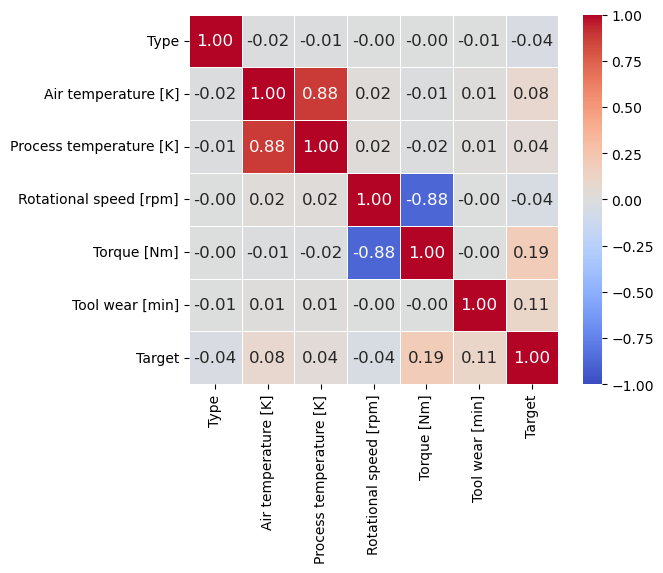

In [38]:
# Visualização da matriz de correlação para a variável de Target
df_exp9_t = df1.copy()
df_exp9_t.drop(columns=['Failure Type'], inplace=True)  # Remover a coluna do DataFrame original

corr_matrix = df_exp9_t.corr()  # Gerar a nova matriz de correlação
ax = sns.heatmap(corr_matrix,  annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True, fmt='.2f', annot_kws={'size': 12}, linewidths=.5)
ax

Da análise da matriz de correlação retiramos as seguintes conclusões:  
  
- A variável "Type" tem correlações fracas e próximas de zero com todas as outras variáveis, incluindo a variável "Target". Isso indica que o tipo não tem uma influência significativa nas outras variáveis e pode ser considerada menos relevante para o estudo.  
  
- As variáveis "Air Temperature" e "Process Temperature" estão altamente correlacionadas entre si (correlação de 0.88). Isso indica que essas duas variáveis são fortemente dependentes uma da outra. Portanto, considerar a remoção de uma delas pode ajudar a evitar problemas de multicolinearidade.  
  
- A variável "Rotational speed" tem uma forte correlação negativa com a variável "Torque" (-0.88). Isso sugere que um aumento na velocidade de rotação está associado a uma diminuição no torque. Neste caso, ambas as variáveis podem ser mantidas, pois cada uma contribui com informações distintas para a previsão da existência de falha na máquina.  
  
- As variáveis "Air Temperature", "Process Temperature", "Rotational speed" e "Tool wear" têm correlações moderadas com a variável "Target". Essas correlações sugerem que essas variáveis podem ter algum efeito na variável de saída.


In [39]:
# Valores absolutos de correlação
corr_abs = abs(df_exp9_t.corr()['Target'])
corr_abs


Type                       0.038448
Air temperature [K]        0.083066
Process temperature [K]    0.035997
Rotational speed [rpm]     0.044042
Torque [Nm]                0.193420
Tool wear [min]            0.106337
Target                     1.000000
Name: Target, dtype: float64

Ao realizar a seleção das variáveis, optamos por escolher aquelas com correlação absoluta acima de 0.04. Essa abordagem nos permite eliminar uma das variáveis altamente correlacionadas, como "Air Temperature" e "Process Temperature", a fim de evitar problemas de multicolinearidade. Além disso, ao aplicar esse critério, também eliminamos variáveis que possuem uma correlação baixa com a variável Target. Essa seleção mais criteriosa das variáveis nos ajuda a manter um conjunto de características mais relevante e informativo para a previsão do Target.

In [40]:
selecao = corr_abs[corr_abs > 0.04].index.tolist()

df_selecao = df_exp9_t[selecao]
df_selecao.head()

,Air temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
0,298.1,1551,42.8,0,0
1,298.2,1408,46.3,3,0
2,298.1,1498,49.4,5,0
3,298.2,1433,39.5,7,0
4,298.2,1408,40.0,9,0


In [41]:
# Teste
model = RandomForestClassifier()

X = df_selecao.drop(['Target'], axis = 1)
y = df_selecao['Target']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=55,stratify=None)

treino_modelo(model,X_train, y_train, X_test, y_test)

-----------------------------------------------
Matriz de Confusão:
[[2879   16]
 [  49   48]]
-----------------------------------------------
   accuracy   f1_score  precision    recall
0  97.82754  79.255533  86.663251  74.46593
-----------------------------------------------


###### Variável Failure Type  (4ª Experiência)

<AxesSubplot:>

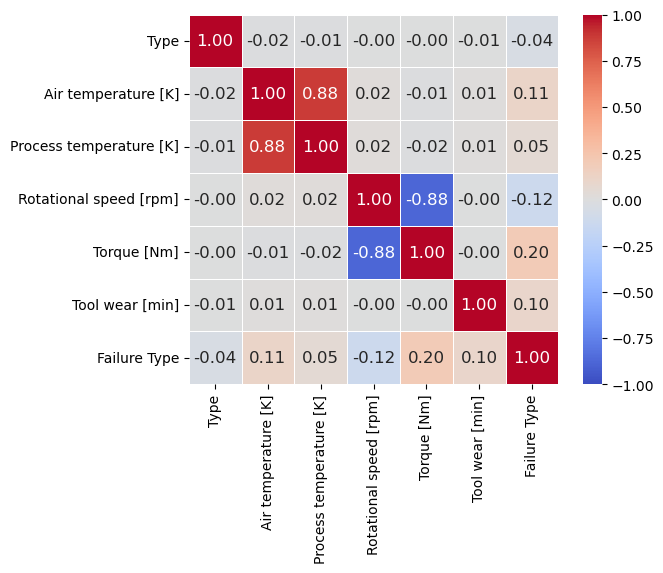

In [42]:
# Visualização da matriz de correlação para a variável Failure Type
df_exp9_f = df1.copy()
df_exp9_f.drop(columns=['Target'], inplace=True)  # Remover a coluna do DataFrame original

corr_matrix = df_exp9_f.corr()  # Gerar a nova matriz de correlação
ax = sns.heatmap(corr_matrix,  annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True, fmt='.2f', annot_kws={'size': 12}, linewidths=.5)
ax

As conclusões são exatamente iguais às da matriz de correlação anterior.

In [43]:
# Valores absolutos de correlação
corr_abs = abs(df_exp9_f.corr()['Failure Type'])
corr_abs

Type                       0.039841
Air temperature [K]        0.110903
Process temperature [K]    0.049028
Rotational speed [rpm]     0.117205
Torque [Nm]                0.198465
Tool wear [min]            0.098256
Failure Type               1.000000
Name: Failure Type, dtype: float64

In [44]:
selecao = corr_abs[corr_abs > 0.05].index.tolist()

df_selecao = df_exp9_f[selecao]
df_selecao.head()

,Air temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type
0,298.1,1551,42.8,0,0
1,298.2,1408,46.3,3,0
2,298.1,1498,49.4,5,0
3,298.2,1433,39.5,7,0
4,298.2,1408,40.0,9,0


In [45]:
# Teste
model = RandomForestClassifier()

X = df_selecao.drop(['Failure Type'], axis = 1)
y = df_selecao['Failure Type']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=55,stratify=None)

treino_modelo(model,X_train, y_train, X_test, y_test)

-----------------------------------------------
Matriz de Confusão:
[[2878    2    0    4   11]
 [   4   19    0    0    0]
 [  13    0    0    1    0]
 [  14    0    0   13    1]
 [  25    0    0    3    4]]
-----------------------------------------------
    accuracy   f1_score  precision    recall
0  97.393048  50.967834  75.094459  48.19001
-----------------------------------------------


#### 5ª Experiência (Escalonamento + Oversampling)

In [46]:
df_over = df_exp2.copy()

###### Variável Target  (5ª experência)

In [47]:
oversampling_target(df_over)

Percentagem de oversampling: 10.0 %
Média Precision: 90.77
Média Recall: 85.01
Média F1-score: 87.63
Média Accuracy: 98.52
-------------------------------
Percentagem de oversampling: 20.0 %
Média Precision: 87.46
Média Recall: 87.51
Média F1-score: 87.42
Média Accuracy: 98.38
-------------------------------
Percentagem de oversampling: 30.0 %
Média Precision: 85.08
Média Recall: 89.12
Média F1-score: 86.96
Média Accuracy: 98.23
-------------------------------
Percentagem de oversampling: 40.0 %
Média Precision: 82.62
Média Recall: 88.53
Média F1-score: 85.28
Média Accuracy: 97.95
-------------------------------
Percentagem de oversampling: 50.0 %
Média Precision: 80.52
Média Recall: 89.2
Média F1-score: 84.22
Média Accuracy: 97.68
-------------------------------
Percentagem de oversampling: 60.0 %
Média Precision: 79.61
Média Recall: 89.28
Média F1-score: 83.65
Média Accuracy: 97.55
-------------------------------


Com base nos resultados fornecidos, onde cada percentagem (10%, 20%, 30%, 40%, 50% e 60%) de oversampling é testada e avaliada usando as métricas: Precision, Recall e F1-score, podemos analisar as métricas para identificar a melhor percentagem de oversampling para o seu objetivo de identificar máquinas com falhas.  
  
Os resultados podem variar à medida que o código é executado, no entanto para controlar melhor essa situação, fizemos 5 repetições e calculámos as médias das métricas, obtendo os seguintes resultados:
  
A percentagem de oversampling de 10% possui uma média de Precision de 91.63, Recall de 85.26, F1-score de 88.1 e Accuracy de 98.46.  
A percentagem de oversampling de 20% possui uma média de Precision de 86.89, Recall de 87.74, F1-score de 87.28 e Accuracy de 98.34.  
A percentagem de oversampling de 30% possui uma média de Precision de 83.68, Recall de 88.45, F1-score de 85.86 e Accuracy de 98.06.  
A percentagem de oversampling de 40% possui uma média de Precision de 81.43, Recall de 88.25, F1-score de 84.44 e Accuracy de 97.79.  
A percentagem de oversampling de 50% possui uma média de Precision de 80.92, Recall de 89.31, F1-score de 84.54 e Accuracy de 97.74.  
A percentagem de oversampling de 60% possui uma média de Precision de 79.97, Recall de 89.5, F1-score de 83.95 e Accuracy de 97.61.  
  
Considerando que o objetivo é identificar as máquinas com falhas, é importante ter um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, fornecendo uma visão geral do desempenho do modelo.  
  
Analisando os resultados, podemos observar que a percentagem de oversampling de 10% apresenta um bom equilíbrio entre a precisão (91.63) e o recall (85.26). Além disso, possui um F1-score médio de 88.1, que é uma medida adequada para avaliar o desempenho geral do modelo.  
  
Portanto, com base nas métricas apresentadas e considerando o objetivo de identificar as máquinas com falhas, a percentagem de oversampling de 10% parece ser a melhor escolha, pois oferece um bom equilíbrio entre precisão e recall, o que é essencial para identificar corretamente as máquinas com falhas.  

###### Variável Failure Type  (5ª experência)

In [48]:
oversampling_failure(df_over)

Percentagem de oversampling: 10.0 %
Matriz de Confusão:
[[2874    3    8    1    3]
 [   6   22    0    2    0]
 [  13    0    0    0    0]
 [   9    0    0   15    0]
 [   8    1    0    0   27]]
Precision: 71.34
Recall: 62.06
F1-score: 66.19
Accuracy: 98.2
-------------------------------
Percentagem de oversampling: 20.0 %
Matriz de Confusão:
[[2857    4   22    2    4]
 [   5   23    0    2    0]
 [  13    0    0    0    0]
 [   8    0    0   15    1]
 [   3    1    0    0   32]]
Precision: 69.31
Recall: 65.39
F1-score: 67.14
Accuracy: 97.83
-------------------------------
Percentagem de oversampling: 30.0 %
Matriz de Confusão:
[[2847    6   28    3    5]
 [   3   25    1    1    0]
 [  12    0    1    0    0]
 [   6    0    0   17    1]
 [   5    1    0    0   30]]
Precision: 68.97
Recall: 68.75
F1-score: 68.6
Accuracy: 97.59
-------------------------------
Percentagem de oversampling: 40.0 %
Matriz de Confusão:
[[2845    6   29    4    5]
 [   3   25    1    1    0]
 [  11    0   

Para a variável de saída "Failure Type", foram testadas as mesmas percentagens e avaliadas as mesmas métricas. Os resultados obtidos foram os seguintes:
  
A percentagem de oversampling de 10% possui uma média de Precision de 71.26, Recall de 61.49, F1-score de 65.81 e Accuracy de 98.06.    
A percentagem de oversampling de 20% possui uma média de Precision de 69.48, Recall de 66.22, F1-score de 67.6 e Accuracy de 97.86.    
A percentagem de oversampling de 30% possui uma média de Precision de 71.08, Recall de 67.55, F1-score de 68.99 e Accuracy de 97.63.    
A percentagem de oversampling de 40% possui uma média de Precision de 72.13, Recall de 74.03, F1-score de 72.3 e Accuracy de 97.66.    
A percentagem de oversampling de 50% possui uma média de Precision de 69.96, Recall de 71.63, F1-score de 70.29 e Accuracy de 97.46.    
A percentagem de oversampling de 60% possui uma média de Precision de 70.38, Recall de 73.03, F1-score de 70.8 e Accuracy de 97.36.    
    
Considerando que o objetivo é identificar as máquinas com falhas, é importante encontrar um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, proporcionando uma visão geral do desempenho do modelo.  

Portanto, podemos observar que a percentagem de oversampling de 40% apresenta um resultado ligeiramente melhor em termos de F1-score.

#### 6ª Experiência (Escalonamento + Seleção de variáveis + Oversampling)

###### Variável Target  (6ª experência)

In [49]:
# Visualização da matriz de correlação para a variável de Target
df_exp9_t = df_exp2.copy()

corr_abs = abs(df_exp9_t.corr()['Target'])
selecao = corr_abs[corr_abs > 0.04].index.tolist()
df_over = df_exp9_t[selecao]

oversampling_target(df_over)

Percentagem de oversampling: 10.0 %
Média Precision: 79.71
Média Recall: 79.23
Média F1-score: 79.42
Média Accuracy: 97.38
-------------------------------
Percentagem de oversampling: 20.0 %
Média Precision: 76.99
Média Recall: 82.52
Média F1-score: 79.44
Média Accuracy: 97.09
-------------------------------
Percentagem de oversampling: 30.0 %
Média Precision: 76.11
Média Recall: 84.45
Média F1-score: 79.63
Média Accuracy: 96.98
-------------------------------
Percentagem de oversampling: 40.0 %
Média Precision: 75.13
Média Recall: 84.92
Média F1-score: 79.11
Média Accuracy: 96.8
-------------------------------
Percentagem de oversampling: 50.0 %
Média Precision: 74.17
Média Recall: 84.6
Média F1-score: 78.33
Média Accuracy: 96.61
-------------------------------
Percentagem de oversampling: 60.0 %
Média Precision: 73.78
Média Recall: 85.21
Média F1-score: 78.23
Média Accuracy: 96.54
-------------------------------


Com base nos resultados fornecidos, onde cada percentagem (10%, 20%, 30%, 40%, 50% e 60%) de oversampling é testada e avaliada usando as métricas: Precision, Recall e F1-score, podemos analisar as métricas para identificar a melhor percentagem de oversampling para o seu objetivo de identificar máquinas com falhas.  
  
Os resultados podem variar à medida que o código é executado, no entanto para controlar melhor essa situação, fizemos 5 repetições e calculámos as médias das métricas, obtendo os seguintes resultados:
  
A percentagem de oversampling de 10% possui uma média de Precision de 79.56, Recall de 78.77, F1-score de 79.13 e Accuracy de 97.36.  
A percentagem de oversampling de 20% possui uma média de Precision de 77.06, Recall de 82.2, F1-score de 79.36 e Accuracy de 97.11.  
A percentagem de oversampling de 30% possui uma média de Precision de 76.16, Recall de 84.53, F1-score de 79.68 e Accuracy de 96.99.  
A percentagem de oversampling de 40% possui uma média de Precision de 75.25, Recall de 85.03, F1-score de 79.24 e Accuracy de 96.82.  
A percentagem de oversampling de 50% possui uma média de Precision de 73.97, Recall de 84.21, F1-score de 78.07 e Accuracy de 96.58.  
A percentagem de oversampling de 60% possui uma média de Precision de 73.86, Recall de 85.13, F1-score de 78.26 e Accuracy de 96.56.  
  
Considerando que o objetivo é identificar as máquinas com falhas, é importante ter um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, fornecendo uma visão geral do desempenho do modelo.  
  
Analisando os resultados, podemos observar que a percentagem de oversampling de 30% apresenta um bom equilíbrio entre a precisão (76.16) e o recall (84.53). Além disso, possui um F1-score médio de 79.68, que é uma medida adequada para avaliar o desempenho geral do modelo.  
  
Portanto, com base nas métricas apresentadas e considerando o objetivo de identificar as máquinas com falhas, a percentagem de oversampling de 30% parece ser a melhor escolha, pois oferece um bom equilíbrio entre precisão e recall, o que é essencial para identificar corretamente as máquinas com falhas. 

###### Variável Failure Type  (6ª experência)

In [50]:
# Visualização da matriz de correlação para a variável Failure Type
df_exp9_f = df_exp2.copy()

corr_abs = abs(df_exp9_f.corr()['Failure Type'])
selecao = corr_abs[corr_abs > 0.04].index.tolist()
df_over = df_exp9_t[selecao]

oversampling_failure(df_over)


Percentagem de oversampling: 10.0 %
Matriz de Confusão:
[[2869    4   10    4    2]
 [   6   21    0    3    0]
 [  13    0    0    0    0]
 [  10    0    0   14    0]
 [   4    1    0    0   31]]
Precision: 68.05
Recall: 62.75
F1-score: 65.23
Accuracy: 98.09
-------------------------------
Percentagem de oversampling: 20.0 %
Matriz de Confusão:
[[2860    3   17    6    3]
 [   4   23    0    3    0]
 [  13    0    0    0    0]
 [   8    0    0   16    0]
 [   4    0    0    0   32]]
Precision: 68.58
Recall: 66.24
F1-score: 67.32
Accuracy: 97.96
-------------------------------
Percentagem de oversampling: 30.0 %
Matriz de Confusão:
[[2844    6   27    9    3]
 [   3   24    0    3    0]
 [  13    0    0    0    0]
 [   7    0    0   17    0]
 [   5    1    0    0   30]]
Precision: 65.19
Recall: 66.52
F1-score: 65.71
Accuracy: 97.43
-------------------------------
Percentagem de oversampling: 40.0 %
Matriz de Confusão:
[[2850    5   24    7    3]
 [   2   25    0    3    0]
 [  12    0 

Para a variável de saída "Failure Type", foram testadas as mesmas percentagens e avaliadas as mesmas métricas. Os resultados obtidos foram os seguintes:
  
A percentagem de oversampling de 10% possui uma média de Precision de 69.49, Recall de 62.97, F1-score de 65.99 e Accuracy de 98.06.    
A percentagem de oversampling de 20% possui uma média de Precision de 67.17, Recall de 65.42, F1-score de 66.24 e Accuracy de 97.96.    
A percentagem de oversampling de 30% possui uma média de Precision de 65.05, Recall de 66.52, F1-score de 65.71 e Accuracy de 97.43.    
A percentagem de oversampling de 40% possui uma média de Precision de 65.47, Recall de 69.12, F1-score de 67.04 e Accuracy de 97.56.    
A percentagem de oversampling de 50% possui uma média de Precision de 66.38, Recall de 69.71, F1-score de 67.59 e Accuracy de 97.43.    
A percentagem de oversampling de 60% possui uma média de Precision de 65.95, Recall de 69.79, F1-score de 67.6 e Accuracy de 97.33.    
    
Considerando que o objetivo é identificar as máquinas com falhas, é importante encontrar um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, proporcionando uma visão geral do desempenho do modelo.  

Portanto, podemos observar que a percentagem de oversampling de 60% apresenta um resultado ligeiramente melhor em termos de F1-score.

### Análise geral das experiências realizadas

### Variável Target

Após realizadas as experiências obtemos os seguintes resultados para cada uma:

###### 1ª Experiência (Sem nada):  
  
    accuracy   f1_score  precision    recall    
     98.46       85.23     94.56       79.28  
    
###### 2ª Experiencia (Escalonamento):  
  
    accuracy   f1_score  precision    recall    
     98.66       87.61    95.07        82.37 
    
###### 3ª Experiência (Oversampling):  
  
Desta experiência resultou que o oversampling de 10% obteve melhores resultados:  
  
    accuracy   f1_score  precision    recall    
     98.46       87.61    89.19        86.24
       
###### 4ª Experiência (Seleção de variáveis):  
  
    accuracy   f1_score  precision    recall    
     97.60       76.60    84.32        71.85
    
###### 5ª Experiência (Escalonamento + Oversampling):
  
Desta experiência resultou que o escalonamento + oversampling de 10% obteve melhores resultados:         
       
    accuracy   f1_score  precision    recall    
     98.46       88.1     91.63        85.26 

###### 6ª Experiência (Escalonamento + Seleção de variáveis + Oversampling):  
  
Desta experiência resultou que o escalonamento + seleção de variáveis + oversampling de 30% obteve melhores resultados:


    accuracy   f1_score  precision    recall    
     96.99       79.68     76.16       84.53      
       
    
    

Considerando que o objetivo é identificar as máquinas com falhas, é importante ter um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, fornecendo uma visão geral do desempenho do modelo.

Analisando os resultados das diferentes experiências, podemos observar que o melhor pré-processamento para a variável de saída Target é a experiência 5, que consiste em utilizar o escalonamento e o oversampling com uma taxa de 10%. Nessa configuração, o modelo alcançou um F1-score de 88.1.  
  
Portanto, para a variável Target vamos utilizar o pré-processamento que consiste em utilizar o escalonamento e o oversampling com uma taxa de 10%.

### Variável Failure Type

Após realizadas as experiências obtemos os seguintes resultados para cada uma:

###### 1ª Experiência (Sem nada):  
  
    accuracy   f1_score  precision    recall    
     98.23       60.80     91.44       54.76  
    
###### 2ª Experiencia (Escalonamento):  
  
    accuracy   f1_score  precision    recall    
     98.53       65.38    91.94        60.57 
    
###### 3ª Experiência (Oversampling):  
  
Desta experiência resultou que o oversampling de 50% obteve melhores resultados:  
  
    accuracy   f1_score  precision    recall    
     97.43       71.14    70.01        73.98
       
###### 4ª Experiência (Seleção de variáveis):  
  
    accuracy   f1_score  precision    recall    
     98.36       63.80    88.98        59.82
    
###### 5ª Experiência (Escalonamento + Oversampling):
  
Desta experiência resultou que o escalonamento + oversampling de 40% obteve melhores resultados:         
       
    accuracy   f1_score  precision    recall    
     97.66       72.3     72.13        74.03 

###### 6ª Experiência (Escalonamento + Seleção de variáveis + Oversampling):  
  
Desta experiência resultou que o escalonamento + seleção de variáveis + oversampling de 60% obteve melhores resultados:


    accuracy   f1_score  precision    recall    
     97.33       67.6     65.95       69.79      
       

Considerando que o objetivo é identificar as máquinas com falhas, é importante ter um equilíbrio entre a precisão e o recall. O F1-score é uma medida que combina essas duas métricas, fornecendo uma visão geral do desempenho do modelo.

Analisando os resultados das diferentes experiências, podemos observar que o melhor pré-processamento para a variável de saída Failure Type é a experiência 5, que consiste em utilizar o escalonamento e o oversampling com uma taxa de 40%. Nessa configuração, o modelo alcançou um F1-score de 72.3.  
  
Portanto, para a variável Failure Type vamos utilizar o pré-processamento que consiste em utilizar o escalonamento e o oversampling com uma taxa de 40%.

Vamos então aplicar o melhor pré-processamento identificado nas experiências para utilizarmos na etapa de modelização.

### Pré-processamento variável Target

In [51]:
df_esc = df_exp2.copy() # escalonamento

# Definir as variáveis de entrada (features) e a variável alvo (target)
X = df_esc.drop(['Target', 'Failure Type'], axis=1)  # Variáveis de entrada
y = df_esc['Target']  # Variável alvo

smote = SMOTE(sampling_strategy=0.1, random_state=0) # oversampling 10 %
X_target, y_target = smote.fit_resample(X, y)

### Pré-processamento variável Target

In [52]:
df_esc = df_exp2.copy() # escalonamento

# Definir as variáveis de entrada (features) e a variável alvo (target)
X = df_esc.drop(['Target', 'Failure Type'], axis=1)  # Variáveis de entrada
y = df_esc['Failure Type']  # Variável alvo

# Calcular o número de amostras necessário para as classes minoritárias
minoritaria_count = int((0.4 / 4) * len(y))

# Definir a estratégia de oversampling para as classes minoritárias
balance_cause = {
    1: minoritaria_count,
    2: minoritaria_count,
    3: minoritaria_count,
    4: minoritaria_count
}

smote = SMOTE(sampling_strategy= balance_cause, random_state=0) # oversampling 40 %
X_failure, y_failure = smote.fit_resample(X, y)

<a id="2"></a>
<h1 style='background:#87d3f8;border:0; color:black;
    box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.75);
    transform: rotateX(10deg);
    '><center style='color: #1f262a;'>Modelização e Validação</center></h1>

In [53]:
def validacao(model, X_train, y_train, X_test,y_test):
    
    model.fit(X_train, y_train) # treino do modelo
    
    predictions = model.predict(X_test) # calculo das previsões

    # criação das métricas para avaliar o modelo
    accuracy = accuracy_score(y_test, predictions) * 100
    f1 = f1_score(y_test, predictions, average='macro') * 100
    precision = precision_score(y_test, predictions, average='macro', zero_division = 0) * 100
    recall = recall_score(y_test, predictions, average='macro') * 100
    
    # criação de um dataframe para a visualização dos resultados
    resul = pd.DataFrame([[accuracy, f1, precision, recall]], columns=['accuracy', 'f1_score', 'precision', 'recall'])
    return resul, predictions

### Variável Target

##### Divisão dos dados (30% dos dados para teste)

Divisão dos dados em dois conjuntos independentes: dados de treino e dados de teste

In [54]:
X_train_target, X_test_target, y_train_target, y_test_target = train_test_split(X_target, y_target, test_size=0.30, random_state=55)

##### Support Vector Machine (SVM)

In [77]:
clf_svm = SVC()

param_grid = {
    'C': [10,100,1000],
    'kernel':['linear', 'poly', 'sigmoid'], 
    'gamma': ['scale', 'auto'] 
}

grid_search = GridSearchCV(clf_svm, param_grid)
grid_search.fit(X_train_target, y_train_target)


# Imprimir os melhores hiperparâmetros
print("Melhores hiperparâmetros: ", grid_search.best_params_)

Melhores hiperparâmetros:  {'C': 1000, 'gamma': 'scale', 'kernel': 'poly'}


Melhores hiperparâmetros SVM: C=10, gamma= scale e kernel= poly

In [78]:
clf_svm = SVC(C= 10, gamma= 'scale', kernel= 'poly')

resultados, y_prev_svm_target = validacao(clf_svm,X_train_target, y_train_target, X_test_target, y_test_target)

resultados.index = ['SVM']
resultados

,accuracy,f1_score,precision,recall
SVM,96.638391,88.193231,90.244102,86.381643


##### Neural Networks (NN)

In [79]:
# Classe do modelo
class Model:
    def __init__(self):
        self.model = None

    def build(self, lr=0.05):
        self.model = Sequential()
        self.model.add(Dense(128, activation='relu'))
        self.model.add(Dense(1, activation='sigmoid'))
        self.model.add(Dense(36, activation='relu'))
        self.model.add(Dense(1, activation='sigmoid'))

        sgd = SGD(lr)
        self.model.compile(optimizer=sgd, loss='binary_crossentropy')

    def train(self, X, Y, epochs=50, batch=128):
        self.model.fit(X, Y, epochs=epochs, batch_size=batch)

    def predict(self, x):
        return self.model.predict(x)


# Criar uma instância do modelo
model_instance = Model()

# Construir o modelo
model_instance.build()

# Treinar o modelo com os dados de treino
model_instance.train(X_train_target, y_train_target, epochs=50, batch=128)

# Previsões usando o modelo
y_prev_NN = model_instance.predict(X_test_target)

# Converter as previsões para formato binário (0 ou 1)
y_prev_NN_target = [1 if p >= 0.5 else 0 for p in y_prev_NN]

# criação das métricas para avaliar o modelo
accuracy = accuracy_score(y_test_target, y_prev_NN_target) * 100
f1 = f1_score(y_test_target, y_prev_NN_target, average='macro') * 100
precision = precision_score(y_test_target, y_prev_NN_target, average='macro', zero_division=0) * 100
recall = recall_score(y_test_target, y_prev_NN_target, average='macro') * 100

# criação de um dataframe para a visualização dos resultados
resul = pd.DataFrame([[accuracy, f1, precision, recall]], columns=['accuracy', 'f1_score', 'precision', 'recall'])
resul


Epoch 1/50
58/58 [==============================] - 1s 2ms/step - loss: 0.4687
Epoch 2/50
58/58 [==============================] - 0s 2ms/step - loss: 0.3287
Epoch 3/50
58/58 [==============================] - 0s 2ms/step - loss: 0.3140
Epoch 4/50
58/58 [==============================] - 0s 3ms/step - loss: 0.3106
Epoch 5/50
58/58 [==============================] - 0s 2ms/step - loss: 0.3084
Epoch 6/50
58/58 [==============================] - 0s 2ms/step - loss: 0.3062
Epoch 7/50
58/58 [==============================] - 0s 2ms/step - loss: 0.3038
Epoch 8/50
58/58 [==============================] - 0s 2ms/step - loss: 0.3012
Epoch 9/50
58/58 [==============================] - 0s 2ms/step - loss: 0.2984
Epoch 10/50
58/58 [==============================] - 0s 2ms/step - loss: 0.2953
Epoch 11/50
58/58 [==============================] - 0s 2ms/step - loss: 0.2921
Epoch 12/50
58/58 [==============================] - 0s 2ms/step - loss: 0.2887
Epoch 13/50
58/58 [==============================

,accuracy,f1_score,precision,recall
0,94.030789,73.148066,87.03648,67.543271


##### Random Forest

Além dos modelos anteriores, decidimos utilizar o classificador Random Forest devido à sua capacidade de lidar bem com classes desbalanceadas.

In [63]:
clf_rc = RandomForestClassifier()


param_grid = {
    'n_estimators':[100,200,300],
    'criterion':['gini', 'entropy', 'log_loss'],
    'max_depth':[None,10,20,30],
    'random_state':[None,34,52] 
}

grid_search = GridSearchCV(clf_rc, param_grid)
grid_search.fit(X_train_target, y_train_target)


# Imprimir os melhores hiperparâmetros
print("Melhores hiperparâmetros: ", grid_search.best_params_)

C:\Users\Daniel Monteiro\anaconda\lib\site-packages\sklearn\model_selection\_validation.py:372: FitFailedWarning:


180 fits failed out of a total of 540.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
180 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Daniel Monteiro\anaconda\lib\site-packages\sklearn\model_selection\_validation.py", line 680, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\Daniel Monteiro\anaconda\lib\site-packages\sklearn\ensemble\_forest.py", line 450, in fit
    trees = Parallel(
  File "C:\Users\Daniel Monteiro\anaconda\lib\site-packages\joblib\parallel.py", line 1085, in __call__
    if self.dispatch_one_batch(iterator):
  File "C:\Us

Melhores hiperparâmetros:  {'criterion': 'entropy', 'max_depth': 20, 'n_estimators': 300, 'random_state': 52}


Melhores hiperparâmetros:  {'criterion': 'entropy', 'max_depth': 20, 'n_estimators': 300, 'random_state': 52}

In [80]:
clf_rc = RandomForestClassifier(criterion='entropy', max_depth=20, n_estimators=300, random_state=52)

resultados, y_prev_rc_target = validacao(clf_rc,X_train_target, y_train_target, X_test_target, y_test_target)

resultados.index = ['RF'] 
resultados

,accuracy,f1_score,precision,recall
RF,98.617656,95.242359,96.609137,93.969096


##### Matriz de confusão

<AxesSubplot:title={'center':'Matriz de Confusão Random Forest'}>

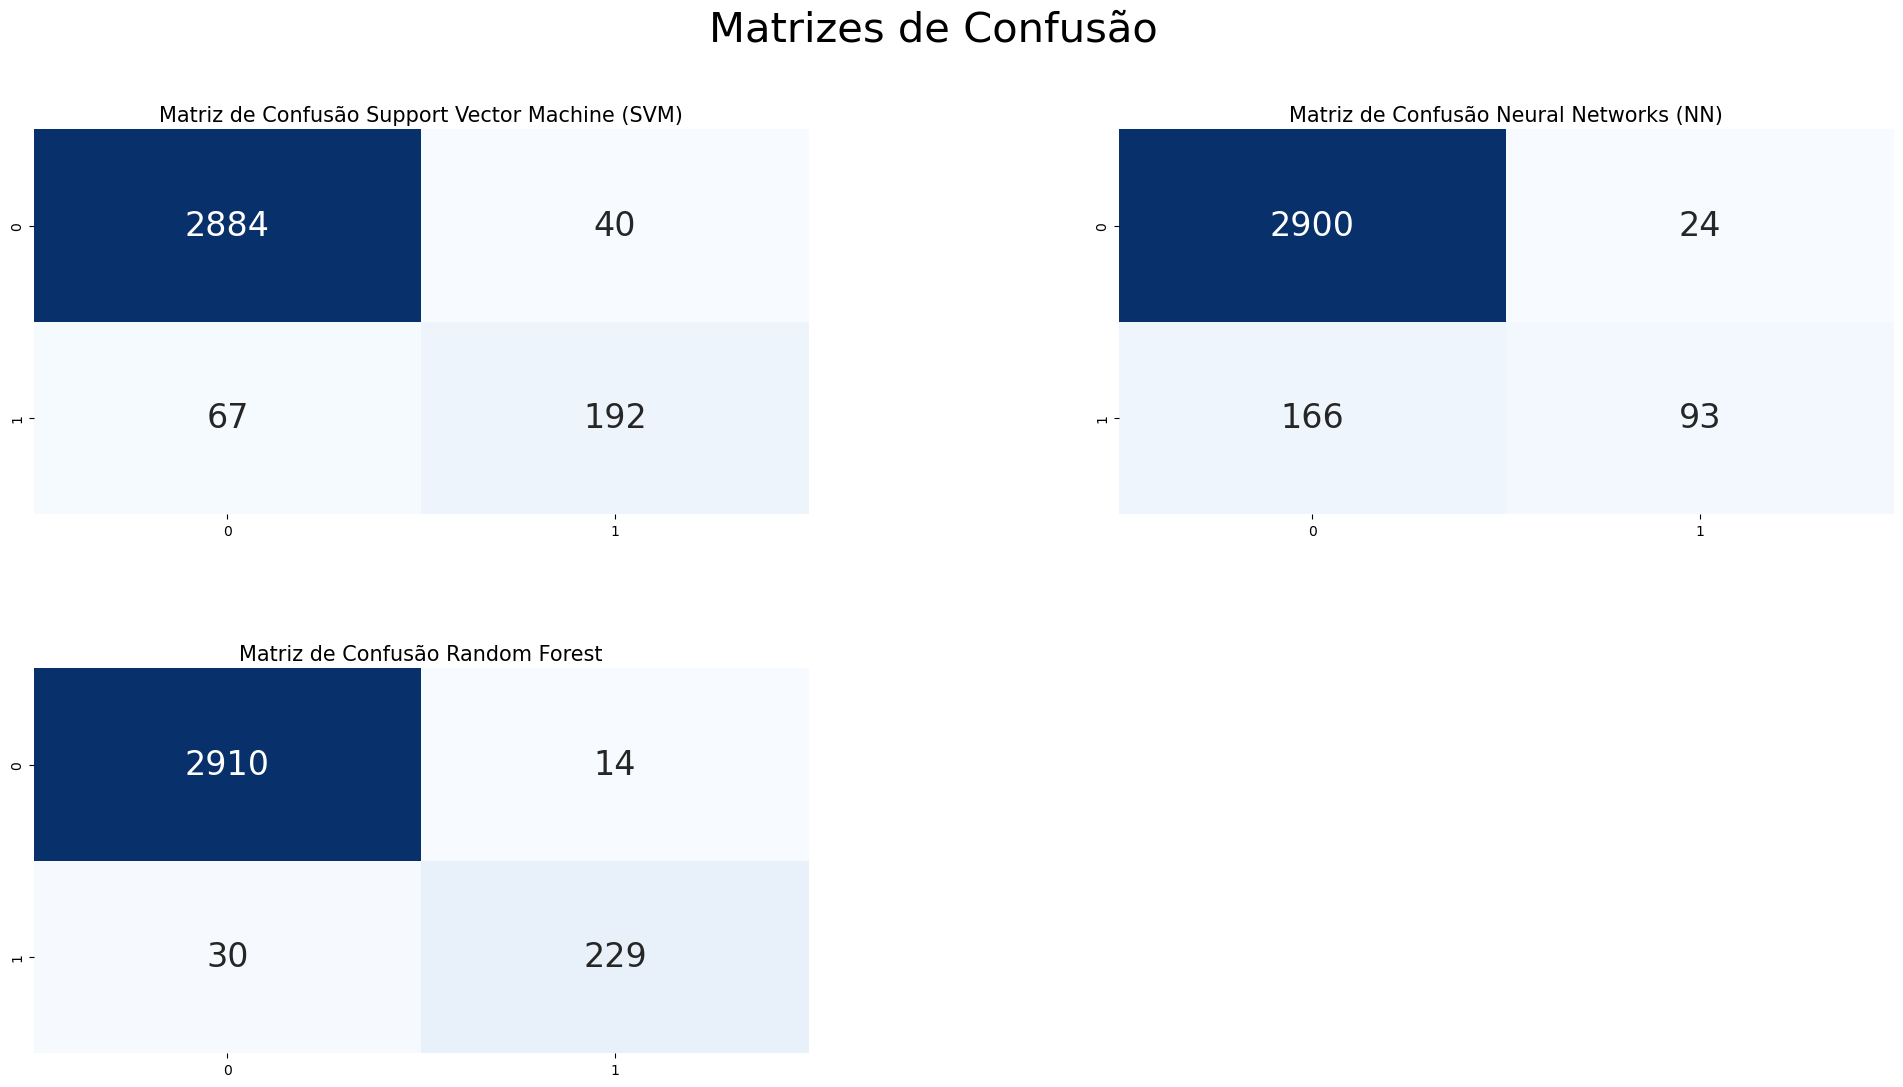

In [82]:
mc_svm_target = confusion_matrix(y_test_target, y_prev_svm_target)
mc_NN_target = confusion_matrix(y_test_target, y_prev_NN_target)
mc_rc_target = confusion_matrix(y_test_target, y_prev_rc_target)

plt.figure(figsize=(24,12))

plt.suptitle("Matrizes de Confusão",fontsize=30)
plt.subplots_adjust(wspace = 0.4, hspace= 0.4)

plt.subplot(2,2,1)
plt.title("Matriz de Confusão Support Vector Machine (SVM)", fontsize=15)
sns.heatmap(mc_svm_target,annot=True,cmap="Blues",fmt="d",cbar=False, annot_kws={"size": 24})

plt.subplot(2,2,2)
plt.title("Matriz de Confusão Neural Networks (NN)", fontsize=15)
sns.heatmap(mc_NN_target,annot=True,cmap="Blues",fmt="d",cbar=False, annot_kws={"size": 24})

plt.subplot(2,2,3)
plt.title("Matriz de Confusão Random Forest", fontsize=15)
sns.heatmap(mc_rc_target,annot=True,cmap="Blues",fmt="d",cbar=False, annot_kws={"size": 24})

### Variável Failure Type

##### Divisão dos dados (30% dos dados para teste)

In [83]:
X_train_failure, X_test_failure, y_train_failure, y_test_failure = train_test_split(X_failure, y_failure, test_size=0.30, random_state=55)

##### Support Vector Machine (SVM)

In [ ]:
clf_svm = SVC()

param_grid = {
    'C': [10,100,1000],
    'kernel':['linear', 'poly', 'sigmoid'], 
    'gamma': ['scale', 'auto'] 
}

grid_search = GridSearchCV(clf_svm, param_grid)
grid_search.fit(X_train_failure, y_train_failure)


# Imprimir os melhores hiperparâmetros
print("Melhores hiperparâmetros: ", grid_search.best_params_)

Melhores hiperparâmetros SVM: C=10, gamma= scale e kernel= poly

In [84]:
clf_svm = SVC(C= 10, gamma= 'scale', kernel= 'poly')

resultados, y_prev_svm_failure = validacao(clf_svm,X_train_failure, y_train_failure, X_test_failure, y_test_failure)

resultados.index = ['SVM']
resultados

,accuracy,f1_score,precision,recall
SVM,95.94132,93.544353,92.411408,94.744665


##### Neural Networks (NN)

In [85]:
# Classe do modelo
class Model:
    def __init__(self):
        self.model = None

    def build(self, lr=0.05):
        self.model = Sequential()
        self.model.add(Dense(128, activation='relu'))
        self.model.add(Dense(5, activation='sigmoid'))
        self.model.add(Dense(36, activation='relu'))
        self.model.add(Dense(5, activation='softmax'))

        sgd = SGD(lr)
        self.model.compile(optimizer=sgd, loss='categorical_crossentropy')

    def train(self, X, Y, epochs=50, batch=128):
        self.model.fit(X, Y, epochs=epochs, batch_size=batch)

    def predict(self, x):
        return self.model.predict(x)

# Criar uma instância do modelo
model_instance = Model()

# Construçao o modelo
model_instance.build()

# Criar uma instância do codificador
encoder = OneHotEncoder()

# Ajustar e transformar os dados de treino
y_train_encoded = encoder.fit_transform(y_train_failure.values.reshape(-1, 1)).toarray()

# Ajustar e transformar os dados de teste
y_test_encoded = encoder.transform(y_test_failure.values.reshape(-1, 1)).toarray()

# Treinar o modelo com os dados de treinamento codificados
model_instance.train(X_train_failure, y_train_encoded, epochs=50, batch=128)

# Fazer previsões usando o modelo
y_pred_encoded = model_instance.predict(X_test_failure)

# Decodificar as previsões para obter as classes previstas
y_prev_NN_failure = encoder.inverse_transform(y_pred_encoded)

# Cálculo das métricas para avaliar o modelo
accuracy = accuracy_score(y_test_failure, y_prev_NN_failure) * 100
f1 = f1_score(y_test_failure, y_prev_NN_failure, average='macro') * 100
precision = precision_score(y_test_failure, y_prev_NN_failure, average='macro', zero_division=0) * 100
recall = recall_score(y_test_failure, y_prev_NN_failure, average='macro') * 100

# Criação de um dataframe para a visualização dos resultados
resul = pd.DataFrame([[accuracy, f1, precision, recall]], columns=['accuracy', 'f1_score', 'precision', 'recall'])
resul


Epoch 1/50
75/75 [==============================] - 1s 3ms/step - loss: 1.0664
Epoch 2/50
75/75 [==============================] - 0s 3ms/step - loss: 0.9631
Epoch 3/50
75/75 [==============================] - 0s 2ms/step - loss: 0.9195
Epoch 4/50
75/75 [==============================] - 0s 3ms/step - loss: 0.8733
Epoch 5/50
75/75 [==============================] - 0s 2ms/step - loss: 0.8299
Epoch 6/50
75/75 [==============================] - 0s 2ms/step - loss: 0.7939
Epoch 7/50
75/75 [==============================] - 0s 3ms/step - loss: 0.7666
Epoch 8/50
75/75 [==============================] - 0s 3ms/step - loss: 0.7455
Epoch 9/50
75/75 [==============================] - 0s 3ms/step - loss: 0.7284
Epoch 10/50
75/75 [==============================] - 0s 3ms/step - loss: 0.7139
Epoch 11/50
75/75 [==============================] - 0s 3ms/step - loss: 0.7003
Epoch 12/50
75/75 [==============================] - 0s 2ms/step - loss: 0.6882
Epoch 13/50
75/75 [==============================

,accuracy,f1_score,precision,recall
0,88.875306,78.045798,82.8235,75.626164


##### Random Forest

In [ ]:
clf_rc = RandomForestClassifier()


param_grid = {
    'n_estimators':[100,200,300],
    'criterion':['gini', 'entropy', 'log_loss'],
    'max_depth':[None,10,20,30],
    'random_state':[None,34,52] 
}

grid_search = GridSearchCV(clf_rc, param_grid)
grid_search.fit(X_train_target, y_train_target)


# Imprimir os melhores hiperparâmetros
print("Melhores hiperparâmetros: ", grid_search.best_params_)

Melhores hiperparâmetros: {'criterion': 'entropy', 'max_depth': 20, 'n_estimators': 300, 'random_state': 52}

In [86]:
clf_rc = RandomForestClassifier(criterion='entropy', max_depth=20, n_estimators=300, random_state=52) 

resultados, y_prev_rc_failure = validacao(clf_rc,X_train_failure, y_train_failure, X_test_failure, y_test_failure)

resultados.index = ['RF'] 
resultados

,accuracy,f1_score,precision,recall
RF,98.215159,97.219035,96.057606,98.497227


#### Matriz de Confusão

<AxesSubplot:title={'center':'Matriz de Confusão Random Forest'}>

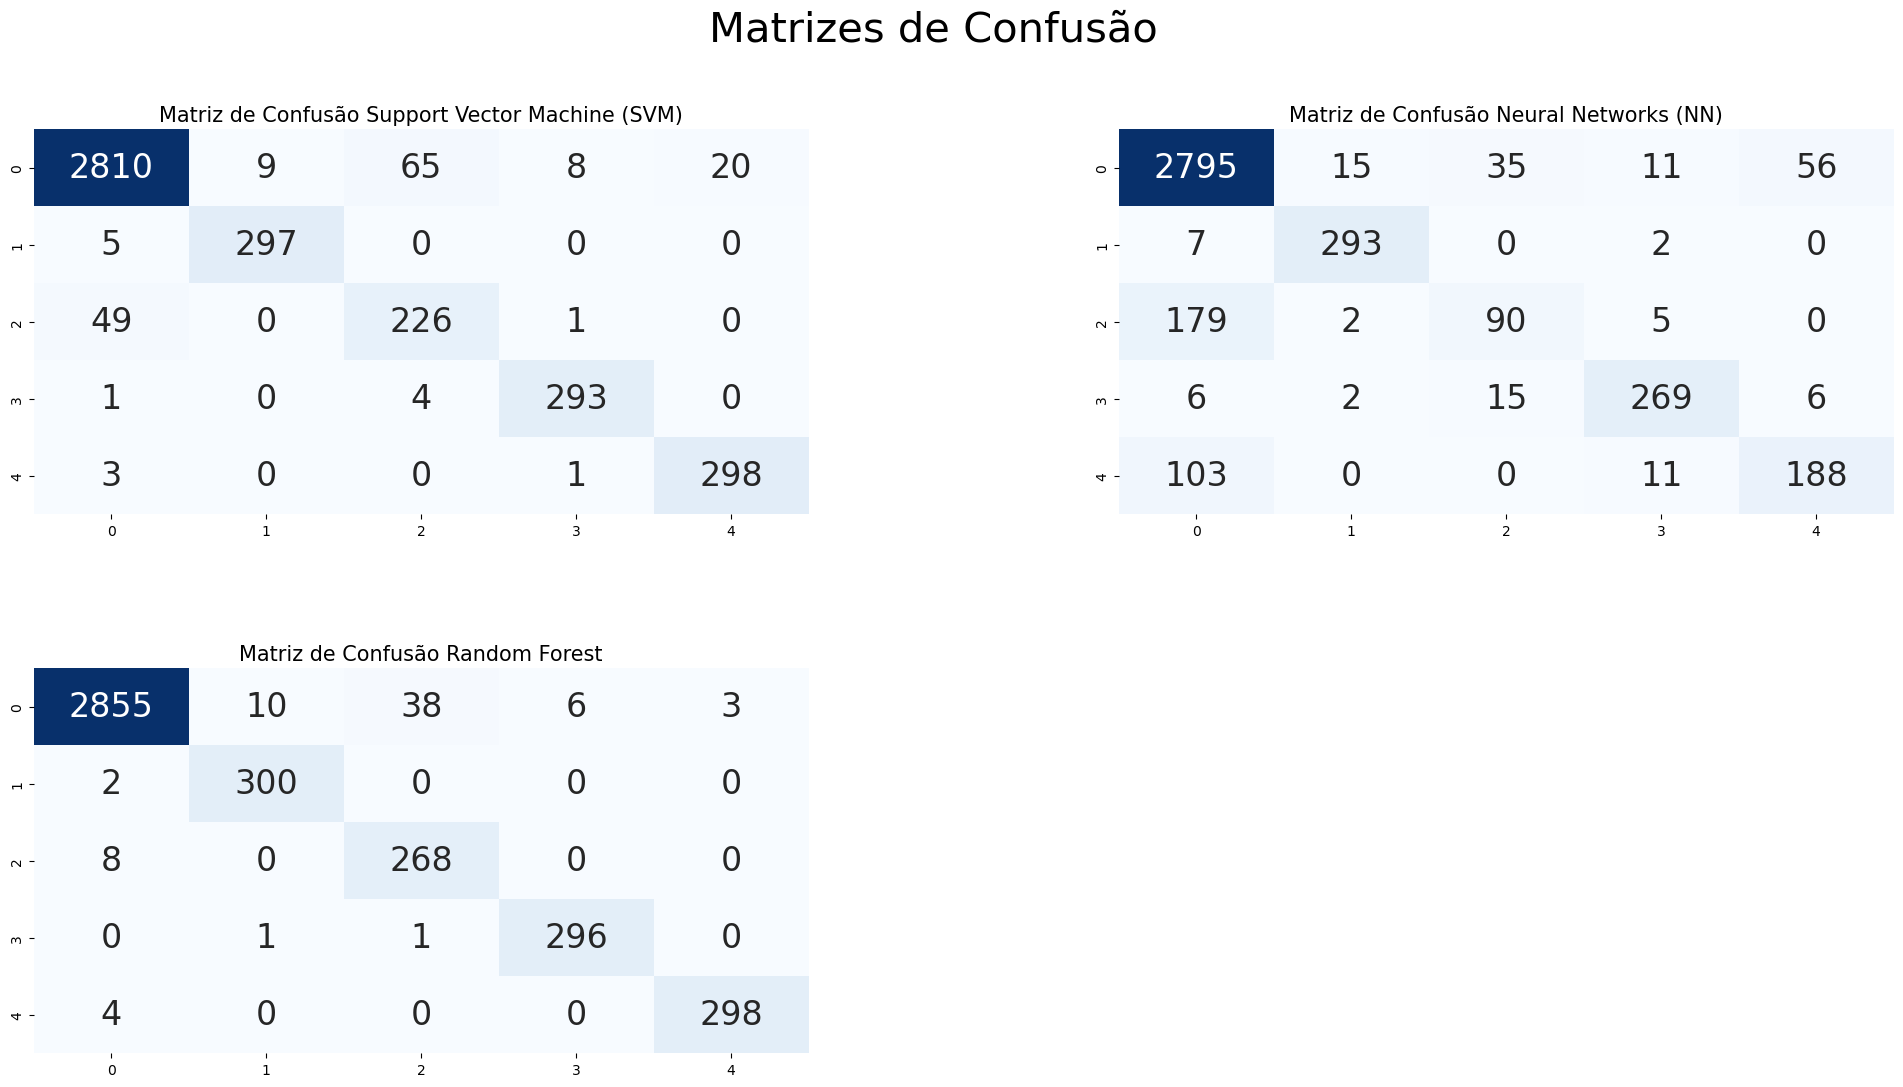

In [87]:
mc_svm_failure = confusion_matrix(y_test_failure, y_prev_svm_failure)
mc_NN_failure = confusion_matrix(y_test_failure, y_prev_NN_failure)
mc_rc_failure = confusion_matrix(y_test_failure, y_prev_rc_failure)

plt.figure(figsize=(24,12))

plt.suptitle("Matrizes de Confusão",fontsize=30)
plt.subplots_adjust(wspace = 0.4, hspace= 0.4)

plt.subplot(2,2,1)
plt.title("Matriz de Confusão Support Vector Machine (SVM)", fontsize=15)
sns.heatmap(mc_svm_failure,annot=True,cmap="Blues",fmt="d",cbar=False, annot_kws={"size": 24})

plt.subplot(2,2,2)
plt.title("Matriz de Confusão Neural Networks (NN)", fontsize=15)
sns.heatmap(mc_NN_failure,annot=True,cmap="Blues",fmt="d",cbar=False, annot_kws={"size": 24})

plt.subplot(2,2,3)
plt.title("Matriz de Confusão Random Forest", fontsize=15)
sns.heatmap(mc_rc_failure,annot=True,cmap="Blues",fmt="d",cbar=False, annot_kws={"size": 24})